## This code is for  diagnosis using autoencoder

### Import necessary library files

In [1]:
import os
from os import environ
environ["CUDA_DEVICE_ORDER"]="PCI_BUS_ID"
environ['CUDA_VISIBLE_DEVICES'] = '0' #Select the GPU Card


print('Process id: ',os.getpid())

import os, os.path, time
import time as time
import timeit

from sys import argv
import sys



########### Load Keras Modules Needed ==========================================
import keras
import tensorflow as tf
import tensorflow.keras
import tensorflow.keras.backend as K

from tensorflow.keras import layers
from tensorflow.keras.models import Sequential, load_model, Model

from tensorflow.keras.layers import GlobalAveragePooling2D, GlobalMaxPooling2D, \
                                    concatenate, average, add, Reshape, Permute, Conv2D, \
                                    Conv2DTranspose, SeparableConv2D,PReLU, ELU, \
                                    BatchNormalization, \
                                    MaxPooling2D, ZeroPadding2D, UpSampling2D, \
                                    AveragePooling2D,Cropping2D, \
                                    Flatten, Dense, Dropout, Activation, Reshape,\
                                    SpatialDropout2D,Average, Concatenate


from tensorflow.keras.optimizers import RMSprop, SGD, Adam
from tensorflow.keras.regularizers import l2
from tensorflow.keras.callbacks import ModelCheckpoint, ReduceLROnPlateau, EarlyStopping,\
                            LearningRateScheduler, Callback
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.utils import plot_model,to_categorical,Sequence


# Load other functions ==================================================
import glob
import csv
import pandas
import pandas as pd
import math as math

import numpy as np
from numpy import zeros, newaxis
import h5py, pickle
from random import randint, choice, shuffle, sample
from itertools import product

from ipywidgets import interact, interactive, fixed, interact_manual
import ipywidgets as widgets
from scipy import signal 



### Load image processing functions.============================================
import cv2
from cv2 import imread, imwrite

import copy

from PIL import Image, ImageOps
import imageio
import matplotlib.pyplot as plot
import matplotlib.pyplot as plt
from matplotlib.ticker import NullFormatter
from matplotlib.gridspec import GridSpec
from matplotlib import offsetbox

from sklearn import manifold, datasets, decomposition, ensemble,\
                     discriminant_analysis, random_projection, neighbors
from sklearn.datasets import make_classification
from sklearn.utils import resample
from sklearn.metrics import accuracy_score, classification_report, roc_auc_score, roc_curve, auc, precision_recall_curve, average_precision_score
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import Pipeline
from sklearn.model_selection import cross_val_score, StratifiedKFold, cross_val_predict
from sklearn.pipeline import Pipeline
# from sklearn.svm import SVC
from sklearn.svm import SVC
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_curve, auc
import umap

# print(keras.__version__)
# print(tf.__version__)


Process id:  318893


2026-03-17 15:07:44.986758: I tensorflow/core/util/port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2026-03-17 15:07:44.998784: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:477] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1773740265.013923  318893 cuda_dnn.cc:8310] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1773740265.018795  318893 cuda_blas.cc:1418] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
2026-03-17 15:07:45.033986: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instr

# Segmentataion of OCT image

In [2]:
def process_label(label_file):
    """
    This fucntion takes label files with layers marked from 1 to 8, not 0 to 7
    """
    colors = np.zeros((9,3),dtype=np.uint8)

    #### Define colors for each label
    colors[0] = [255, 255, 255]  # Background (white)
    colors[1] = [255, 0, 0]      # Class 1 (Red)
    colors[2] = [0, 255, 0]      # Class 2 (Green)
    colors[3] = [0, 0, 255]      # Class 3 (Blue)
    colors[4] = [75, 0, 130]     # Class 4 (Indigo)
    colors[5] = [255, 165, 0]    # Class 5 (Orange)
    colors[6] = [255, 255, 0]    # Class 6 (Yellow)      
    colors[7] = [238, 130, 238]  # Class 7 (Violet)

    H = np.shape(label_file)[0]
    W = np.shape(label_file)[1]

    img = np.zeros((H,W,3),dtype=np.uint8)
    for i,j in product(range(H),range(W)):
        img[i, j] = colors[label_file[i,j]]

    return np.asarray(img)

In [3]:
import tensorflow.keras.backend as K

# Convolutional block (2 convs)
def conv_block(x, filters):
    x = layers.Conv2D(filters, 3, padding='same', activation='relu')(x)
    x = layers.Conv2D(filters, 3, padding='same', activation='relu')(x)
    return x

# Attention gate with static resizing
def attention_gate(x, g, inter_channels):
    x_shape = K.int_shape(x)
    g = layers.Resizing(x_shape[1], x_shape[2])(g)

    theta_x = layers.Conv2D(inter_channels, 1, padding='same')(x)
    phi_g = layers.Conv2D(inter_channels, 1, padding='same')(g)

    add = layers.Add()([theta_x, phi_g])
    relu = layers.Activation('relu')(add)
    psi = layers.Conv2D(1, 1, padding='same')(relu)
    sigmoid = layers.Activation('sigmoid')(psi)

    return layers.Multiply()([x, sigmoid])

# Resize decoder output to match encoder skip connection
def resize_like(source, target):
    target_shape = K.int_shape(target)
    return layers.Resizing(target_shape[1], target_shape[2])(source)

# Main Attention UNet function
def attention_unet(img_rows, img_cols, num_classes=1):
    inputs = tf.keras.Input(shape=(img_rows, img_cols, 1))

    # Encoder
    c1 = conv_block(inputs, 64)
    p1 = layers.MaxPooling2D()(c1)

    c2 = conv_block(p1, 128)
    p2 = layers.MaxPooling2D()(c2)

    c3 = conv_block(p2, 256)
    p3 = layers.MaxPooling2D()(c3)

    c4 = conv_block(p3, 512)
    p4 = layers.MaxPooling2D()(c4)

    # Bottleneck
    bn = conv_block(p4, 1024)

    # Decoder with attention and resizing
    u4 = layers.UpSampling2D(interpolation='bilinear')(bn)
    att4 = attention_gate(c4, u4, 512)
    u4 = resize_like(u4, att4)
    m4 = layers.Concatenate()([u4, att4])
    d4 = conv_block(m4, 512)

    u3 = layers.UpSampling2D(interpolation='bilinear')(d4)
    att3 = attention_gate(c3, u3, 256)
    u3 = resize_like(u3, att3)
    m3 = layers.Concatenate()([u3, att3])
    d3 = conv_block(m3, 256)

    u2 = layers.UpSampling2D(interpolation='bilinear')(d3)
    att2 = attention_gate(c2, u2, 128)
    u2 = resize_like(u2, att2)
    m2 = layers.Concatenate()([u2, att2])
    d2 = conv_block(m2, 128)

    u1 = layers.UpSampling2D(interpolation='bilinear')(d2)
    att1 = attention_gate(c1, u1, 64)
    u1 = resize_like(u1, att1)
    m1 = layers.Concatenate()([u1, att1])
    d1 = conv_block(m1, 64)

    # Output layer
    outputs = layers.Conv2D(num_classes, 1, activation='softmax')(d1)

    model = Model(inputs, outputs)
    return model


def vertical_penalty_loss(y_true, y_pred, penalty_weight=0.1):
    """
    Adds a vertical penalty loss to enforce ordering of class labels.

    Parameters:
    - y_true: Ground truth labels, one-hot encoded (not used directly in loss).
    - y_pred: Predicted labels, logits, or probabilities with shape (batch, height, width, classes).
    - penalty_weight: Weight of the vertical penalty term.

    Returns:
    - Penalty loss value.
    """
    # Compute difference along the vertical axis (height axis)
    diff = y_pred[:, 1:, :, :] - y_pred[:, :-1, :, :]

    # Penalize negative differences (ordering violation)
    penalty = tf.keras.backend.relu(-diff)

    # Compute the mean penalty and scale it
    penalty_loss = penalty_weight * tf.keras.backend.mean(tf.keras.backend.sum(penalty, axis=-1))

    return penalty_loss





img_rows=200; img_cols=400
nb_classes = 8

Adam= tf.keras.optimizers.Adam(learning_rate=0.0005, beta_1=0.9, beta_2=0.999, decay=0.0, amsgrad=False)  ###............
model =  attention_unet(img_rows,img_cols,nb_classes)


model.compile(optimizer= Adam, loss=lambda y_true, y_pred: tf.keras.losses.categorical_crossentropy(y_true, y_pred) + vertical_penalty_loss(y_true, y_pred), metrics = ['accuracy'])
model.summary()

/home/suraj/Suraj_env/lib/python3.10/site-packages/keras/src/optimizers/base_optimizer.py:86: UserWarning: Argument `decay` is no longer supported and will be ignored.
  warnings.warn(
I0000 00:00:1773740275.476861  318893 gpu_device.cc:2022] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 20833 MB memory:  -> device: 0, name: NVIDIA A10, pci bus id: 0000:17:00.0, compute capability: 8.6


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 200, 400,  │          0 │ -                 │
│ (InputLayer)        │ 1)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d (Conv2D)     │ (None, 200, 400,  │        640 │ input_layer[0][0] │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_1 (Conv2D)   │ (None, 200, 400,  │     36,928 │ conv2d[0][0]      │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d       │ (None, 100, 200,  │          0 │ conv2d_1[0][0]    │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_2 (Conv2D)   │ (None, 100, 200,  │     73,856 │ max_pooling2d[0]… │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_3 (Conv2D)   │ (None, 100, 200,  │    147,584 │ conv2d_2[0][0]    │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_1     │ (None, 50, 100,   │          0 │ conv2d_3[0][0]    │
│ (MaxPooling2D)      │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_4 (Conv2D)   │ (None, 50, 100,   │    295,168 │ max_pooling2d_1[… │
│                     │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_5 (Conv2D)   │ (None, 50, 100,   │    590,080 │ conv2d_4[0][0]    │
│                     │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_2     │ (None, 25, 50,    │          0 │ conv2d_5[0][0]    │
│ (MaxPooling2D)      │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_6 (Conv2D)   │ (None, 25, 50,    │  1,180,160 │ max_pooling2d_2[… │
│                     │ 512)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_7 (Conv2D)   │ (None, 25, 50,    │  2,359,808 │ conv2d_6[0][0]    │
│                     │ 512)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_3     │ (None, 12, 25,    │          0 │ conv2d_7[0][0]    │
│ (MaxPooling2D)      │ 512)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_8 (Conv2D)   │ (None, 12, 25,    │  4,719,616 │ max_pooling2d_3[… │
│                     │ 1024)             │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_9 (Conv2D)   │ (None, 12, 25,    │  9,438,208 │ conv2d_8[0][0]    │
│                     │ 1024)             │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ up_sampling2d       │ (None, 24, 50,    │          0 │ conv2d_9[0][0]    │
│ (UpSampling2D)      │ 1024)             │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ resizing (Resizing) │ (None, 25, 50,    │          0 │ up_sampling2d[0]

 Total params: 32,425,612 (123.69 MB)

 Trainable params: 32,425,612 (123.69 MB)

 Non-trainable params: 0 (0.00 B)

In [4]:
# model = load_model('./Model_checkpoints/'+testname+'.keras')
model.load_weights('/mnt/DATA/sda1/Suraj/New directory/Model_checkpoints/best_weights_Attention_UNet_cce_pf_1.weights.h5')


/home/suraj/Suraj_env/lib/python3.10/site-packages/keras/src/saving/saving_lib.py:797: UserWarning: Skipping variable loading for optimizer 'adam', because it has 2 variables whereas the saved optimizer has 126 variables. 
  saveable.load_own_variables(weights_store.get(inner_path))


In [5]:
path = '/mnt/DATA/sda1/Suraj/data/PS_OCT_SANKARA/Images_Glaucoma/'
imgpath = sorted(glob.glob(path + 'IMAGES/*.jpg'))

print("Total files:", len(imgpath))

batch_size = 5
all_preds = []
all_imgs  = []   # store images

for i in range(0, len(imgpath), batch_size):

    batch_files = imgpath[i:i+batch_size]
    batch_imgs = []

    for f in batch_files:
        img = Image.open(f).convert('L').resize((400, 200))
        img = np.array(img, dtype=np.float32)

        img = np.expand_dims(img, axis=2)

        # normalize safely
        if np.max(img) > np.min(img):
            img = (img - np.min(img)) / (np.max(img) - np.min(img))

        batch_imgs.append(img)

    batch_imgs = np.array(batch_imgs, dtype=np.float32)

    preds = model.predict(batch_imgs, verbose=0)

    all_imgs.append(batch_imgs)     # store images
    all_preds.append(preds)

# combine everything
img_array = np.concatenate(all_imgs, axis=0)
img_label_glau = np.concatenate(all_preds, axis=0)

print(img_array.shape)
print(img_label_glau.shape)


Total files: 96


I0000 00:00:1773740277.043155  319089 service.cc:148] XLA service 0x7f1094010800 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1773740277.043202  319089 service.cc:156]   StreamExecutor device (0): NVIDIA A10, Compute Capability 8.6
2026-03-17 15:07:57.106173: I tensorflow/compiler/mlir/tensorflow/utils/dump_mlir_util.cc:268] disabling MLIR crash reproducer, set env var `MLIR_CRASH_REPRODUCER_DIRECTORY` to enable.
I0000 00:00:1773740277.221582  319089 cuda_dnn.cc:529] Loaded cuDNN version 91002
E0000 00:00:1773740278.398919  319089 gpu_timer.cc:82] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
E0000 00:00:1773740278.560056  319089 gpu_timer.cc:82] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
E0000 00:00:1773740278.937548  319089 gpu_timer.cc

(96, 200, 400, 1)
(96, 200, 400, 8)


In [6]:
# path = '/mnt/DATA/sda1/Suraj/Glaucoma/'
# imgpath = sorted(glob.glob(path + '*.npy'))

# print("Total files:", len(imgpath))

# batch_size = 100
# all_preds = []
# img_array = []
# all_imgs = []

# for i in range(0, len(imgpath), batch_size):

#     batch_files = imgpath[i:i+batch_size]
#     batch_imgs = []

#     for f in batch_files:
#         img = np.load(f)
#         img = cv2.resize(img, (400, 200))

#         if len(img.shape) == 2:
#             img = np.expand_dims(img, axis=2)

#         img = (img - np.min(img)) / (np.max(img) - np.min(img))

#         batch_imgs.append(img)

#     batch_imgs = np.array(batch_imgs, dtype=np.float32)

#     preds = model.predict(batch_imgs, verbose=0)

#     all_imgs.append(batch_imgs)      # store images
#     all_preds.append(preds)

# # combine everything
# img_array = np.concatenate(all_imgs, axis=0)
# img_label_glau = np.concatenate(all_preds, axis=0)

# print(img_array.shape)
# print(img_label_glau.shape)

In [7]:
# @interact(x=(0,len(img_array)-1,1)) #Function responsible for creating the slider. Usage format @interact(start,end,step size)
# def h(x=0): #Starting number of the slider
#     f = plt.figure(figsize=(12,6))

#     f.add_subplot(1,3, 1)
#     plt.imshow(img_array[x,:,:,0], cmap='gray')

#     f.add_subplot(1,3, 2)
#     plt.imshow (process_label(np.argmax(img_label_glau[x], axis = 2))) #cmap='turbo')


#     f.add_subplot(1,3, 3)
#     plt.imshow(img_array[x,:,:,0], cmap='gray')
#     plt.imshow(process_label(np.argmax(img_label_glau[x], axis=2)), alpha=0.25) #cmap='turbo', alpha = 0.25)

#     plt.show()

In [8]:
# path = '/mnt/DATA/sda1/Suraj/Healthy/'
# imgpath = sorted(glob.glob(path + '*.npy'))

# print("Total files:", len(imgpath))

# batch_size = 100
# all_preds = []
# img_array = []
# all_imgs = []

# for i in range(0, len(imgpath), batch_size):

#     batch_files = imgpath[i:i+batch_size]
#     batch_imgs = []

#     for f in batch_files:
#         img = np.load(f)
#         img = cv2.resize(img, (400, 200))

#         if len(img.shape) == 2:
#             img = np.expand_dims(img, axis=2)

#         img = (img - np.min(img)) / (np.max(img) - np.min(img))

#         batch_imgs.append(img)

#     batch_imgs = np.array(batch_imgs, dtype=np.float32)

#     preds = model.predict(batch_imgs, verbose=0)

#     all_imgs.append(batch_imgs)      # store images
#     all_preds.append(preds)

# # combine everything
# img_array = np.concatenate(all_imgs, axis=0)
# img_label_heal = np.concatenate(all_preds, axis=0)

# print(img_array.shape)
# print(img_label_heal.shape)

In [9]:
path = '/mnt/DATA/sda1/Suraj/data/PS_OCT_SANKARA/Images_Normal/'
imgpath = sorted(glob.glob(path + 'IMAGES/*.jpg'))

print("Total files:", len(imgpath))

batch_size = 5
all_preds = []
all_imgs = []

for i in range(0, len(imgpath), batch_size):

    batch_files = imgpath[i:i+batch_size]
    batch_imgs = []

    for tpath in batch_files:
        try:
            img = Image.open(tpath).convert('L').resize((400,200))
            img = np.array(img, dtype=np.float32)
            img = np.expand_dims(img, axis=2)

            # normalization
            if np.max(img) > np.min(img):
                img = (img - np.min(img)) / (np.max(img) - np.min(img))

            batch_imgs.append(img)

        except Exception as e:
            print("Error loading:", tpath, e)

    if len(batch_imgs) == 0:
        continue

    batch_imgs = np.array(batch_imgs, dtype=np.float32)

    preds = model.predict(batch_imgs, verbose=0)

    # store both
    all_imgs.append(batch_imgs)
    all_preds.append(preds)

# Combine everything
img_array = np.concatenate(all_imgs, axis=0)
img_label_heal = np.concatenate(all_preds, axis=0)

print("Images shape:", img_array.shape)
print("Predictions shape:", img_label_heal.shape)


Total files: 104
Error loading: /mnt/DATA/sda1/Suraj/data/PS_OCT_SANKARA/Images_Normal/IMAGES/ARUN H N OCT.jpg cannot identify image file '/mnt/DATA/sda1/Suraj/data/PS_OCT_SANKARA/Images_Normal/IMAGES/ARUN H N OCT.jpg'


E0000 00:00:1773740291.274209  319088 gpu_timer.cc:82] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
E0000 00:00:1773740291.435297  319088 gpu_timer.cc:82] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
E0000 00:00:1773740291.794073  319088 gpu_timer.cc:82] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
E0000 00:00:1773740291.992793  319088 gpu_timer.cc:82] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-03-17 15:08:13.759083: W external/local_xla/xla/tsl/framework/bfc_allocator.cc:306] Allocator (GPU_0_bfc) ran out of memory trying to allocate 24.78GiB with freed_by_count=0. The caller indicates that th

Error loading: /mnt/DATA/sda1/Suraj/data/PS_OCT_SANKARA/Images_Normal/IMAGES/VIJAY KUMAR OCT.jpg cannot identify image file '/mnt/DATA/sda1/Suraj/data/PS_OCT_SANKARA/Images_Normal/IMAGES/VIJAY KUMAR OCT.jpg'
Error loading: /mnt/DATA/sda1/Suraj/data/PS_OCT_SANKARA/Images_Normal/IMAGES/shaleen sinhaOCT.jpg cannot identify image file '/mnt/DATA/sda1/Suraj/data/PS_OCT_SANKARA/Images_Normal/IMAGES/shaleen sinhaOCT.jpg'


E0000 00:00:1773740299.450424  319088 gpu_timer.cc:82] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
E0000 00:00:1773740299.610785  319088 gpu_timer.cc:82] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
E0000 00:00:1773740299.946509  319088 gpu_timer.cc:82] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
E0000 00:00:1773740300.144181  319088 gpu_timer.cc:82] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-03-17 15:08:21.347114: W external/local_xla/xla/tsl/framework/bfc_allocator.cc:306] Allocator (GPU_0_bfc) ran out of memory trying to allocate 24.68GiB with freed_by_count=0. The caller indicates that th

Images shape: (101, 200, 400, 1)
Predictions shape: (101, 200, 400, 8)


In [10]:
# @interact(x=(0,len(img_array)-1,1)) #Function responsible for creating the slider. Usage format @interact(start,end,step size)
# def h(x=0): #Starting number of the slider
#     f = plt.figure(figsize=(12,6))

#     f.add_subplot(1,3, 1)
#     plt.imshow(img_array[x,:,:,0], cmap='gray')

#     f.add_subplot(1,3, 2)
#     plt.imshow(process_label(np.argmax(img_label_heal[x], axis = 2)))


#     f.add_subplot(1,3, 3)
#     plt.imshow(img_array[x,:,:,0], cmap='gray')
#     plt.imshow(process_label(np.argmax(img_label_heal[x], axis = 2)), alpha = 0.25)

#     plt.show()

In [11]:
print(np.shape(img_label_heal))
print(np.shape(img_label_glau))

(101, 200, 400, 8)
(96, 200, 400, 8)


### create an object of helper function class

In [12]:
testname="UMAP_Autoencoder_Sankara_noskip"
print(testname)

UMAP_Autoencoder_Sankara_noskip


### working and image directory path

In [13]:
path = os.getcwd()
print(path)

/home/suraj/codes/Codes-20250106T060826Z-001/Codes


### train, val and test data

In [14]:
print(np.shape(img_label_heal))
print(np.shape(img_label_glau))

# print(np.unique(img_label_heal))
# print(np.unique(img_label_glau))

(101, 200, 400, 8)
(96, 200, 400, 8)


In [15]:
train_images  =[]
train_labels=[]
train_diag=[]
train_ids_forplotting = []

for i in range(70):
    train_images.append( np.expand_dims(np.argmax(img_label_heal[i], axis = 2), axis = 2 )) 
    train_labels.append(img_label_heal[i])
    train_diag.append([1,0])
    train_ids_forplotting.append('b')


for i in range(70):
    # train_images.append( np.expand_dims(Normalize( np.argmax(img_label_glau[i], axis = 2) ), axis = 2) )
    train_images.append( np.expand_dims(np.argmax(img_label_glau[i], axis = 2), axis = 2 ))
    train_labels.append(img_label_glau[i])
    train_diag.append([0,1])
    train_ids_forplotting.append('r')


train_images  =np.array(train_images)
train_labels=np.array(train_labels)
train_diag=np.array(train_diag)
train_ids_forplotting = np.array(train_ids_forplotting)


print(np.shape(train_images))
print(np.shape(train_labels))
print(np.shape(train_diag))
print(np.shape(train_ids_forplotting))

# Generate a random permutation of indices
perm = np.random.permutation(140)

# Shuffle all arrays using the same permutation
train_images1 = train_images[perm]
train_labels1 = train_labels[perm]
train_diag1 = train_diag[perm]
train_ids_forplotting1 = train_ids_forplotting[perm]


print(np.shape(train_images1))
print(np.shape(train_labels1))
print(np.shape(train_diag1))
print(np.shape(train_ids_forplotting1))

(140, 200, 400, 1)
(140, 200, 400, 8)
(140, 2)
(140,)
(140, 200, 400, 1)
(140, 200, 400, 8)
(140, 2)
(140,)


In [16]:
val_images  =[]
val_labels=[]
val_diag=[]
val_ids_forplotting = []

for i in range(70,85):
    # val_images.append( np.expand_dims(Normalize( np.argmax(img_label_heal[i], axis = 2) ), axis = 2) )
    val_images.append( np.expand_dims(np.argmax(img_label_heal[i], axis = 2), axis = 2 ))
    val_labels.append(img_label_heal[i])
    val_diag.append([1,0])
    val_ids_forplotting.append('b')


for i in range(70,85):
    # val_images.append( np.expand_dims(Normalize( np.argmax(img_label_glau[i], axis = 2) ), axis = 2) )
    val_images.append( np.expand_dims(np.argmax(img_label_glau[i], axis = 2), axis = 2 )) 
    val_labels.append(img_label_glau[i])
    val_diag.append([0,1])
    val_ids_forplotting.append('r')


val_images  =np.array(val_images)
val_labels=np.array(val_labels)
val_diag=np.array(val_diag)
val_ids_forplotting = np.array(val_ids_forplotting)

print(np.shape(val_images))
print(np.shape(val_labels))
print(np.shape(val_diag))
print(np.shape(val_ids_forplotting))


# Generate a random permutation of indices
perm = np.random.permutation(30)

# Shuffle all arrays using the same permutation
val_images1 = val_images[perm]
val_labels1 = val_labels[perm]
val_diag1 = val_diag[perm]
val_ids_forplotting1 = val_ids_forplotting[perm]


print(np.shape(val_images1))
print(np.shape(val_labels1))
print(np.shape(val_diag1))
print(np.shape(val_ids_forplotting1))

(30, 200, 400, 1)
(30, 200, 400, 8)
(30, 2)
(30,)
(30, 200, 400, 1)
(30, 200, 400, 8)
(30, 2)
(30,)


In [17]:
test_images  =[]
test_labels=[]
test_diag=[]
test_ids_forplotting = []

for i in range(85,101):
    # test_images.append( np.expand_dims(Normalize( np.argmax(img_label_heal[i], axis = 2) ), axis = 2) )
    test_images.append( np.expand_dims(np.argmax(img_label_heal[i], axis = 2), axis = 2 ))
    test_labels.append(img_label_heal[i])
    test_diag.append([1,0])
    test_ids_forplotting.append('b')


for i in range(85,96):
    # test_images.append( np.expand_dims(Normalize( np.argmax(img_label_glau[i], axis = 2) ), axis = 2) )
    test_images.append( np.expand_dims(np.argmax(img_label_glau[i], axis = 2), axis = 2 ))
    test_labels.append(img_label_glau[i])
    test_diag.append([0,1])
    test_ids_forplotting.append('r')


test_images  =np.array(test_images)
test_labels=np.array(test_labels)
test_diag=np.array(test_diag)
test_ids_forplotting = np.array(test_ids_forplotting)

print(np.shape(test_images))
print(np.shape(test_labels))
print(np.shape(test_diag))
print(np.shape(test_ids_forplotting))


# Generate a random permutation of indices
perm = np.random.permutation(27)

# Shuffle all arrays using the same permutation
test_images1 = test_images[perm]
test_labels1 = test_labels[perm]
test_diag1 = test_diag[perm]
test_ids_forplotting1 = test_ids_forplotting[perm]


print(np.shape(test_images1))
print(np.shape(test_labels1))
print(np.shape(test_diag1))
print(np.shape(test_ids_forplotting1))

(27, 200, 400, 1)
(27, 200, 400, 8)
(27, 2)
(27,)
(27, 200, 400, 1)
(27, 200, 400, 8)
(27, 2)
(27,)


 ### Image data

In [18]:
# W, H = 400,200 #dimension of each image from the cirrus device
img_rows, img_cols = 200, 400
nb_classes = 8

### visualization of images

In [19]:
@interact(x=(0,len(test_labels1)-1,1)) #Function responsible for creating the slider. Usage format @interact(start,end,step size)                  
def h(x=0): 
    f = plt.figure(figsize=(12,6))
    sp = f.add_subplot(1, 2, 1)
    plt.imshow(test_images[x,:,:,0])
    
    sp = f.add_subplot(1, 2, 2)
    plt.imshow(np.argmax(test_labels[x], axis = 2))
    plt.show()

interactive(children=(IntSlider(value=0, description='x', max=26), Output()), _dom_classes=('widget-interact',…

### Data generation function

In [20]:
def DataGen(X, y, y_diag, batch_sz, mode=True):

    c = list(zip(X, y, y_diag))
    croph, cropw = img_rows, img_cols

    Xpatches = np.ndarray((batch_sz, croph, cropw, 1), dtype=np.float32)
    ypatches = np.ndarray((batch_sz, croph, cropw, nb_classes), dtype=np.float32)
    y_diag_patch = np.ndarray((batch_sz, 2), dtype=np.uint8)

    image_index = 0
    batch_index = 0

    while True:

        # yield batch when full
        if batch_index == batch_sz:
            batch_index = 0
            yield Xpatches, (ypatches, y_diag_patch)

        # reset dataset
        if image_index >= len(X):
            image_index = 0

        # shuffle at start of epoch
        if image_index == 0:
            shuffle(c)
            X, y, y_diag = zip(*c)

        # copy data
        ax = np.copy(X[image_index])
        ay = np.copy(y[image_index])
        ay_diag = np.copy(y_diag[image_index])

        # ensure correct dtype and memory layout
        ax = np.ascontiguousarray(ax.astype(np.float32))
        ay = np.ascontiguousarray(ay.astype(np.float32))

        # ======================
        # AUGMENTATION (train only)
        # ======================
        if mode:

            # Horizontal flip
            if randint(0, 1):
                ax = ax[:, ::-1, :]
                ay = ay[:, ::-1, :]

            # Random shift
            M = np.float32([
                [1, 0, np.random.uniform(-8, 8)],
                [0, 1, np.random.uniform(-8, 8)]
            ])

            ax[:, :, 0] = cv2.warpAffine(
                ax[:, :, 0],
                M,
                (cropw, croph),
                flags=cv2.INTER_LINEAR,
                borderMode=cv2.BORDER_REFLECT
            )

            for c_idx in range(ay.shape[2]):
                ay[:, :, c_idx] = cv2.warpAffine(
                    ay[:, :, c_idx],
                    M,
                    (cropw, croph),
                    flags=cv2.INTER_NEAREST,
                    borderMode=cv2.BORDER_REFLECT
                )

            # Random rotation
            rotation_matrix = cv2.getRotationMatrix2D(
                (cropw / 2, croph / 2),
                np.random.uniform(-2, 2),
                1
            )

            ax[:, :, 0] = cv2.warpAffine(
                ax[:, :, 0],
                rotation_matrix,
                (cropw, croph),
                flags=cv2.INTER_LINEAR,
                borderMode=cv2.BORDER_REFLECT
            )

            for c_idx in range(ay.shape[2]):
                ay[:, :, c_idx] = cv2.warpAffine(
                    ay[:, :, c_idx],
                    rotation_matrix,
                    (cropw, croph),
                    flags=cv2.INTER_NEAREST,
                    borderMode=cv2.BORDER_REFLECT
                )

        # ======================
        # Store in batch
        # ======================
        Xpatches[batch_index] = ax
        ypatches[batch_index] = ay
        y_diag_patch[batch_index] = ay_diag

        batch_index += 1
        image_index += 1


### Data Generator Sanity Checks

In [21]:
# Generate augmentation 
batch_sz = 5
training_gen = DataGen(train_images1, train_labels1,train_diag1, batch_sz,mode=True)
val_gen = DataGen(val_images1, val_labels1,val_diag1, batch_sz,mode=False)


im,datagen_out = next(training_gen)
print("Dim(image)=",np.shape(im))
print("Dim(Label)=",np.shape(datagen_out[0]))
print("Dim(Diag)=",np.shape(datagen_out[1]))

@interact(x=(0,batch_sz-1,1)) #Function responsible for creating the slider. Usage format @interact(start,end,step size)                  
def h(x=0): #Starting number of the slider
    f = plt.figure(figsize=(12,6))
    sp = f.add_subplot(1, 2, 1)
    plt.imshow(im[x,:,:,0])
    sp = f.add_subplot(1, 2, 2)
    seg = datagen_out[0]
    color_label= process_label(np.argmax(seg[x], axis=2)+1)
    plt.imshow(color_label)
    print(datagen_out[1])

    

Dim(image)= (5, 200, 400, 1)
Dim(Label)= (5, 200, 400, 8)
Dim(Diag)= (5, 2)


interactive(children=(IntSlider(value=0, description='x', max=4), Output()), _dom_classes=('widget-interact',)…

### Autoencoder architecture

In [22]:
NumLyrLtnSpc = 6   # or whatever number of retinal layers you have
num_classes = nb_classes

In [23]:
# # encoder
# encoder_input = tf.keras.Input(shape=(img_rows, img_cols, 1),name="original_img")

# conv1 = encoder_input
   
# conv1 = Conv2D(64, 3, activation = 'elu', padding = 'same', kernel_initializer = 'he_normal')(conv1)
# conv1 = Conv2D(64, 3, activation = 'elu', padding = 'same', kernel_initializer = 'he_normal')(conv1)
# conv1 = MaxPooling2D(pool_size=(2, 2))(conv1)

# conv2 = Conv2D(32, 3, activation = 'elu', padding = 'same', kernel_initializer = 'he_normal')(conv1)
# conv2 = Conv2D(32, 3, activation = 'elu', padding = 'same', kernel_initializer = 'he_normal')(conv2)
# conv2 = MaxPooling2D(pool_size=(2, 2))(conv2)

# conv3 = Conv2D(16, 3, activation = 'elu', padding = 'same', kernel_initializer = 'he_normal')(conv2)
# conv3 = Conv2D(16, 3, activation = 'elu', padding = 'same', kernel_initializer = 'he_normal')(conv3)
# conv3 = MaxPooling2D(pool_size=(2, 2))(conv3)

# conv4 = Conv2D(8, 3, activation = 'elu', padding = 'same', kernel_initializer = 'he_normal')(conv3)
# conv4 = Conv2D(8, 3, activation = 'elu', padding = 'same', kernel_initializer = 'he_normal')(conv4)
# conv4 = MaxPooling2D(pool_size=(2, 2))(conv4)

# conv5 = Conv2D(4, 3, activation = 'elu', padding = 'same', kernel_initializer = 'he_normal')(conv4)
# conv5 = Conv2D(4, 3, activation = 'elu', padding = 'same', kernel_initializer = 'he_normal')(conv5)
# conv5 = MaxPooling2D(pool_size=(2, 2))(conv5)

# conv6 = Conv2D(2, 3, activation = 'elu', padding = 'same', kernel_initializer = 'he_normal')(conv5)
# conv6 = Conv2D(2, 3, activation = 'elu', padding = 'same', kernel_initializer = 'he_normal')(conv6)
# conv6 = MaxPooling2D(pool_size=(2, 2))(conv6)

# conv7 = Conv2D(NumLyrLtnSpc, 2, activation = 'elu', padding = 'same', kernel_initializer = 'he_normal')(conv6)
# conv7 = Conv2D(NumLyrLtnSpc, 2, activation = 'elu', padding = 'same', kernel_initializer = 'he_normal')(conv7)
# conv7 = MaxPooling2D(pool_size=(1, 2))(conv7)

# pool7 = conv7
# # save the output shape for decoder
# encoderout_shape = tf.keras.backend.int_shape(pool7)[1:]

# # Instantiate encoder
# # encoder = Model(inputs = [encoder_input], outputs = [pool7],name='encoder')
# encoder = Model(
#     inputs=encoder_input,
#     outputs=[conv1, conv2, conv3, conv4, conv5, conv6, pool7],
#     name='encoder'
# )


# encoder.summary()
# #encoder
# encoder_input = tf.keras.Input(shape=(img_rows, img_cols, 1),name="original_img")

# conv1 = encoder_input
   
# conv1 = Conv2D(64, 3, activation = 'elu', padding = 'same', kernel_initializer = 'he_normal')(conv1)
# conv1 = Conv2D(64, 3, activation = 'elu', padding = 'same', kernel_initializer = 'he_normal')(conv1)
# conv1 = MaxPooling2D(pool_size=(2, 2))(conv1)

# conv2 = Conv2D(32, 3, activation = 'elu', padding = 'same', kernel_initializer = 'he_normal')(conv1)
# conv2 = Conv2D(32, 3, activation = 'elu', padding = 'same', kernel_initializer = 'he_normal')(conv2)
# conv2 = MaxPooling2D(pool_size=(2, 2))(conv2)

# conv3 = Conv2D(16, 3, activation = 'elu', padding = 'same', kernel_initializer = 'he_normal')(conv2)
# conv3 = Conv2D(16, 3, activation = 'elu', padding = 'same', kernel_initializer = 'he_normal')(conv3)
# conv3 = MaxPooling2D(pool_size=(2, 2))(conv3)

# conv4 = Conv2D(8, 3, activation = 'elu', padding = 'same', kernel_initializer = 'he_normal')(conv3)
# conv4 = Conv2D(8, 3, activation = 'elu', padding = 'same', kernel_initializer = 'he_normal')(conv4)
# conv4 = MaxPooling2D(pool_size=(2, 2))(conv4)

# conv5 = Conv2D(4, 3, activation = 'elu', padding = 'same', kernel_initializer = 'he_normal')(conv4)
# conv5 = Conv2D(4, 3, activation = 'elu', padding = 'same', kernel_initializer = 'he_normal')(conv5)
# conv5 = MaxPooling2D(pool_size=(2, 2))(conv5)

# conv6 = Conv2D(2, 3, activation = 'elu', padding = 'same', kernel_initializer = 'he_normal')(conv5)
# conv6 = Conv2D(2, 3, activation = 'elu', padding = 'same', kernel_initializer = 'he_normal')(conv6)
# conv6 = MaxPooling2D(pool_size=(2, 2))(conv6)

# conv7 = Conv2D(NumLyrLtnSpc, 2, activation = 'elu', padding = 'same', kernel_initializer = 'he_normal')(conv6)
# conv7 = Conv2D(NumLyrLtnSpc, 2, activation = 'elu', padding = 'same', kernel_initializer = 'he_normal')(conv7)
# conv7 = MaxPooling2D(pool_size=(1, 2))(conv7)

# pool7 = conv7
# # save the output shape for decoder
# encoderout_shape = tf.keras.backend.int_shape(pool7)[1:]

# # Instantiate encoder
# encoder = Model(inputs = [encoder_input], outputs = [pool7],name='encoder')

# encoder.summary()

In [24]:
# from tensorflow.keras.layers import Conv2D, UpSampling2D, Concatenate, Lambda
# def build_decoder(num_classes=8):
#     # 7 inputs: c1-c6 + bottleneck
#     c1_in = tf.keras.Input(shape=(img_rows//2, img_cols//2, 64))
#     c2_in = tf.keras.Input(shape=(img_rows//4, img_cols//4, 32))
#     c3_in = tf.keras.Input(shape=(img_rows//8, img_cols//8, 16))
#     c4_in = tf.keras.Input(shape=(img_rows//16, img_cols//16, 8))
#     c5_in = tf.keras.Input(shape=(img_rows//32, img_cols//32, 4))
#     c6_in = tf.keras.Input(shape=(img_rows//64, img_cols//64, 2))
#     bottleneck_in = tf.keras.Input(shape=(img_rows//64, img_cols//128, 6))  # adjust NumLyrLtnSpc

#     def resize_like(x, ref):
#         return Lambda(lambda inputs: tf.image.resize(inputs[0],
#                                                     size=tf.shape(inputs[1])[1:3]))([x, ref])

#     x = bottleneck_in

#     # Stage 6
#     x = UpSampling2D((1,2))(x)
#     x = resize_like(x, c6_in)
#     x = Concatenate()([x, c6_in])
#     x = Conv2D(2, 3, activation='elu', padding='same')(x)
#     x = Conv2D(2, 3, activation='elu', padding='same')(x)

#     # Stage 5
#     x = UpSampling2D((2,2))(x)
#     x = resize_like(x, c5_in)
#     x = Concatenate()([x, c5_in])
#     x = Conv2D(4, 3, activation='elu', padding='same')(x)
#     x = Conv2D(4, 3, activation='elu', padding='same')(x)

#     # Stage 4
#     x = UpSampling2D((2,2))(x)
#     x = resize_like(x, c4_in)
#     x = Concatenate()([x, c4_in])
#     x = Conv2D(8, 3, activation='elu', padding='same')(x)
#     x = Conv2D(8, 3, activation='elu', padding='same')(x)

#     # Stage 3
#     x = UpSampling2D((2,2))(x)
#     x = resize_like(x, c3_in)
#     x = Concatenate()([x, c3_in])
#     x = Conv2D(16, 3, activation='elu', padding='same')(x)
#     x = Conv2D(16, 3, activation='elu', padding='same')(x)

#     # Stage 2
#     x = UpSampling2D((2,2))(x)
#     x = resize_like(x, c2_in)
#     x = Concatenate()([x, c2_in])
#     x = Conv2D(32, 3, activation='elu', padding='same')(x)
#     x = Conv2D(32, 3, activation='elu', padding='same')(x)

#     # Stage 1
#     x = UpSampling2D((2,2))(x)
#     x = resize_like(x, c1_in)
#     x = Concatenate()([x, c1_in])
#     x = Conv2D(64, 3, activation='elu', padding='same')(x)
#     x = Conv2D(64, 3, activation='elu', padding='same')(x)
#     # FINAL UPSAMPLING (this is what you're missing)
#     x = Conv2DTranspose(32, (2,2), strides=(2,2), padding='same')(x)

#     # Output
#     output = Conv2D(num_classes, 1, activation='softmax')(x)

#     decoder_model = Model(
#         inputs=[c1_in, c2_in, c3_in, c4_in, c5_in, c6_in, bottleneck_in],
#         outputs=output,
#         name='decoder'
#     )
#     return decoder_model
# decoder
# decoder_input   = tf.keras.Input(shape=(encoderout_shape),name="encoded_img")

# up8 = Conv2D(6, 2, activation = 'elu', padding = 'same', kernel_initializer = 'he_normal')(UpSampling2D(size = (2,2))(decoder_input))
# conv8 = Conv2D(6, 3, activation = 'elu', padding = 'same', kernel_initializer = 'he_normal')(up8)
# conv8 = Conv2D(6, 3, activation = 'elu', padding = 'same', kernel_initializer = 'he_normal')(conv8)

# up9 = Conv2D(6, 2, activation = 'elu', padding = 'same', kernel_initializer = 'he_normal')(UpSampling2D(size = (1,2))(conv8))
# # up9 = ZeroPadding2D((0,1))(up9) 
# # up9 = Cropping2D(cropping=((0, 0), (0, 1)))(up9) 
# conv9 = Conv2D(6, 3, activation = 'elu', padding = 'same', kernel_initializer = 'he_normal')(up9)
# conv9 = Conv2D(6, 3, activation = 'elu', padding = 'same', kernel_initializer = 'he_normal')(conv9)

# up10 = Conv2D(6, 2, activation = 'elu', padding = 'same', kernel_initializer = 'he_normal')(UpSampling2D(size = (2,2))(conv9))
# up10 = ZeroPadding2D((0,1))(up10) 
# up10 = Cropping2D(cropping=((0, 0), (0, 1)))(up10) 
# conv10 = Conv2D(8, 3, activation = 'elu', padding = 'same', kernel_initializer = 'he_normal')(up10)
# conv10 = Conv2D(8, 3, activation = 'elu', padding = 'same', kernel_initializer = 'he_normal')(conv10)

# up11 = Conv2D(8, 2, activation = 'elu', padding = 'same', kernel_initializer = 'he_normal')(UpSampling2D(size = (2,2))(conv10))
# up11 = ZeroPadding2D((1,0))(up11) 
# up11 = Cropping2D(cropping=((0, 1), (0, 0)))(up11) 
# conv11 = Conv2D(16, 3, activation = 'elu', padding = 'same', kernel_initializer = 'he_normal')(up11)
# conv11 = Conv2D(16, 3, activation = 'elu', padding = 'same', kernel_initializer = 'he_normal')(conv11)

# up12 = Conv2D(16, 2, activation = 'elu', padding = 'same', kernel_initializer = 'he_normal')(UpSampling2D(size = (2,2))(conv11))
# conv12 = Conv2D(32, 3, activation = 'elu', padding = 'same', kernel_initializer = 'he_normal')(up12)
# conv12 = Conv2D(32, 3, activation = 'elu', padding = 'same', kernel_initializer = 'he_normal')(conv12)

# up13 = Conv2D(32, 2, activation = 'elu', padding = 'same', kernel_initializer = 'he_normal')(UpSampling2D(size = (2,2))(conv12))
# conv13 = Conv2D(64, 3, activation = 'elu', padding = 'same', kernel_initializer = 'he_normal')(up13)
# conv13 = Conv2D(64, 3, activation = 'elu', padding = 'same', kernel_initializer = 'he_normal')(conv13)

# conv14 = Conv2D(64, 3, activation = 'elu', padding = 'same', kernel_initializer = 'he_normal')(UpSampling2D(size = (2,2))(conv13))


# conv15 = Conv2D(64, 3, activation = 'elu', padding = 'same', kernel_initializer = 'he_normal')(conv14)
# conv15 = Conv2D(32, 3, activation = 'elu', padding = 'same', kernel_initializer = 'he_normal')(conv15)
# conv15 = Conv2D(16, 3, activation = 'elu', padding = 'same', kernel_initializer = 'he_normal')(conv15)
# conv15 = Conv2D(8, 3, activation = 'elu', padding = 'same', kernel_initializer = 'he_normal')(conv15)

# conv16 = Conv2D(nb_classes, 1, activation = 'softmax')(conv15)


# # Instantiate encoder
# decoder = Model(inputs = [decoder_input], outputs = [conv16],name='decoder')

# decoder.summary()

In [25]:
# # classifier
# classifier_input   = tf.keras.Input(shape=(encoderout_shape),name="encoded_img")

# # diag class 
# flat_x = Flatten()(classifier_input) 
# flat_x = Dense(12,activation='elu',kernel_initializer='he_normal')(flat_x)
# flat_x = Dense(6,activation='elu',kernel_initializer='he_normal')(flat_x)
# flat_x = Dense(2,activation='softmax',kernel_initializer='he_normal')(flat_x)


# # Instantiate encoder
# classifier = Model(inputs = [classifier_input], outputs = [flat_x],name='classifier')

# classifier.summary()
# classifier_input   = tf.keras.Input(shape=(encoderout_shape),name="encoded_img")

# #diag class 
# flat_x = Flatten()(classifier_input) 
# flat_x = Dense(12,activation='elu',kernel_initializer='he_normal')(flat_x)
# flat_x = Dense(6,activation='elu',kernel_initializer='he_normal')(flat_x)
# flat_x = Dense(2,activation='softmax',kernel_initializer='he_normal')(flat_x)


# # Instantiate encoder
# classifier = Model(inputs = [classifier_input], outputs = [flat_x],name='classifier')

# classifier.summary()


In [26]:
# # --------------------------
# # Step 1: Build the 7-input decoder
# # --------------------------
# decoder = build_decoder(num_classes)  # Use the function I provided before

# # --------------------------
# # Step 2: Build the autoencoder
# # --------------------------
# autoencoder_input = tf.keras.Input(shape=(img_rows, img_cols, 1))

# # Get encoder outputs
# c1, c2, c3, c4, c5, c6, bottleneck = encoder(autoencoder_input)

# # Pass through the new decoder
# decoded_out = decoder([c1, c2, c3, c4, c5, c6, bottleneck])

# # If you have a classifier head:
# classifier_out = classifier(bottleneck)  # make sure classifier exists and takes bottleneck

# # Build the full model
# autoencoder = tf.keras.Model(
#     inputs=autoencoder_input,
#     outputs=[decoded_out, classifier_out],
#     name='autoencoder'
# )

# autoencoder.summary()
# autoencoder_input = tf.keras.Input(shape=(img_rows, img_cols, 1))


# latent_space = encoder(autoencoder_input)

# decoded_out = decoder(latent_space)
# classifier_out = classifier(latent_space)


# # Build the complete autoencoder model
# autoencoder = Model(inputs=autoencoder_input, outputs=[decoded_out,classifier_out], name='autoencoder')

# #Compile the model
# autoencoder.summary()


### Build and compile model

In [27]:
losses = {
    "decoder": 'categorical_crossentropy',
    "classifier": "categorical_crossentropy",
}

lossWeights = {"decoder": 2.0, "classifier": 1.0}


In [28]:
Adam =  tf.keras.optimizers.Adam(learning_rate=1e-5, beta_1=0.9, beta_2=0.999, amsgrad=False)  

# autoencoder.compile(optimizer = Adam, 
#                     loss = losses, loss_weights=lossWeights,
#                     metrics = ['accuracy', 'accuracy'])  #....

### Model checkpoints

In [29]:
# class ResizeLike(tf.keras.layers.Layer):
#     def call(self, inputs):
#         x, ref = inputs
#         target_size = tf.shape(ref)[1:3]
#         return tf.image.resize(x, size=target_size)

#     def get_config(self):
#         return super().get_config()

In [30]:
# model = tf.keras.models.load_model(
#     './../../../../../mnt/DATA/sda1/Suraj/New directory/Model_checkpoints/UMAP_Autoencoder.keras',
#     compile=False,
#     custom_objects={"ResizeLike": ResizeLike}
# )

model = tf.keras.models.load_model('./../../../../../mnt/DATA/sda1/Suraj/New directory/Model_checkpoints/UMAP_Autoencoder_noskip.keras')

# best_checkpoint=ModelCheckpoint(filepath='./../../../../../mnt/DATA/sda1/Suraj/New directory' + '/Model_checkpoints/best_weights_' + testname + '.keras',
#                              monitor='val_loss',verbose=1, 
#                              save_best_only=True, save_weights_only=False, mode='min')

# cur_checkpoint=ModelCheckpoint(filepath='./../../../../../mnt/DATA/sda1/Suraj/New directory' + '/Model_checkpoints/cur_weights_'+testname+'.keras',
#                              monitor='val_loss',verbose=0, 
#                              save_best_only=False, save_weights_only=False, mode='min')


In [31]:
# model.compile(
#     optimizer=Adam,
#     loss=losses,
#     loss_weights=lossWeights,
#     metrics={
#         "decoder": [dice_coefficient],
#         "classifier": ["accuracy"]
#     }
# )

### Start training

In [32]:
epochs=500

train_mini_batch_sz =12
val_mini_batch_sz = 6
num_train_batches, num_val_batches = 32, 32

### Epoch 



In [33]:
# Define the tf.data.Dataset from the generator
from tensorflow.keras.callbacks import EarlyStopping
training_gen = tf.data.Dataset.from_generator(
    lambda: DataGen(train_images1, train_labels1, train_diag1, train_mini_batch_sz, mode=True),    
    output_signature=(
        tf.TensorSpec(shape=(train_mini_batch_sz, img_rows, img_cols, 1), dtype=tf.float32),  # Point cloud input
        (
            tf.TensorSpec(shape=(train_mini_batch_sz, img_rows, img_cols, 8), dtype=tf.float32),  # Reconstructed point cloud
            tf.TensorSpec(shape=(train_mini_batch_sz, 2), dtype=tf.int8)          # Labels
        )
    )
)


val_gen = tf.data.Dataset.from_generator(
    lambda: DataGen(val_images1, val_labels1, val_diag1, val_mini_batch_sz, mode=False),
    output_signature=(
        tf.TensorSpec(shape=(val_mini_batch_sz, img_rows, img_cols, 1), dtype=tf.float32),
        (
            tf.TensorSpec(shape=(val_mini_batch_sz, img_rows, img_cols, 8), dtype=tf.float32),
            tf.TensorSpec(shape=(val_mini_batch_sz, 2), dtype=tf.uint8)
        )
    )
)


# early_stop = EarlyStopping(
#     monitor='val_loss',     # monitor validation loss
#     patience=20,            # number of epochs to wait before stopping
#     restore_best_weights=True,  # restore best model weights
#     verbose=1
# )
steps_epoch=80 #train_images.shape[0] // train_mini_batch_sz
val_steps= 20 #val_images.shape[0] // val_mini_batch_sz

# fit_history = model.fit(
#                     x=training_gen,
#                     steps_per_epoch=steps_epoch,
#                     epochs=epochs, 
#                     validation_data=val_gen, 
#                     validation_steps=val_steps,
#                     verbose=1,
#                     callbacks=[best_checkpoint, cur_checkpoint])



### Print epoch history

In [34]:
# print(fit_history.history.keys())
# plt.rcParams['figure.figsize'] = (20,5)

# plt.subplot(1,2,1)
# plt.title("Loss vs epoch")
# #plt.plot(fit_history.history["loss"], "r-*", label='loss')
# plt.plot(fit_history.history["0/decoder_loss"], "b-*", label='decoder_loss')
# plt.plot(fit_history.history["1/classifier_loss"], "r-*", label='classifier_loss')
# plt.legend()
# plt.ylim(0,3)

# plt.subplot(1,2,2)
# plt.title("Acc vs epoch")
# plt.plot(fit_history.history["decoder_dice_coefficient"], "r-*", label='decoder_dice_coefficient')
# plt.plot(fit_history.history["classifier_accuracy"], "b-*", label='classifier_accuracy')
# plt.legend()
# plt.ylim(0,1)

### Save model

In [35]:
# model.save(
#     '/mnt/DATA/sda1/Suraj/New directory/Model_checkpoints/' + testname + '.keras'
# )

### Create a new model and load the best weight for testing

In [36]:
# model = tf.keras.models.load_model(
#     './../../../../../mnt/DATA/sda1/Suraj/New directory/Model_checkpoints/' 
#     + testname + '.keras',
#     compile=False,
#     custom_objects={"ResizeLike": ResizeLike}
# )
# print('model loaded successfully')

# model = tf.keras.models.load_model(
#     './../../../../../mnt/DATA/sda1/Suraj/New directory/Model_checkpoints/' + testname + '.keras',
#     custom_objects={
#         "dice_ce_loss": dice_ce_loss,
#         "dice_loss": dice_loss,
#         "dice_coefficient": dice_coefficient
#     },
#     compile=False
# )
# print('model loaded successfully')

### Obtain Predictions

In [37]:
test_preds = model.predict(test_images1) #obtain predictions for glaucoma

print(np.shape(test_images1))
print(np.shape(test_preds[0][0]))
print(np.shape(test_preds[1][0]))
print('Predictions obtained ....')
pred_masks = test_preds[0]   # segmentation output
pred_class = test_preds[1]   # classifier output

1/1 ━━━━━━━━━━━━━━━━━━━━ 5s 5s/step
(27, 200, 400, 1)
(27, 200, 400, 8)
(27, 2)
Predictions obtained ....


### Output of MLP branch

In [38]:
print(np.shape(test_diag1))
print(np.shape(test_preds[1][0]))
label_data  = test_preds[0]     # reconstructed masks
label_data2 = test_labels1      # ground truth masks
print(np.shape(test_preds[0]))

(27, 2)
(27, 2)
(1, 27, 200, 400, 8)


In [39]:
# from sklearn.metrics import roc_curve, auc
# import matplotlib.pyplot as plt

# # True labels (take positive class column)
# y_true = test_diag1[:, 1]

# # Predicted probabilities (positive class)
# y_score = test_preds[1][0][:, 1]

# fpr, tpr, _ = roc_curve(y_true, y_score)
# roc_auc = auc(fpr, tpr)

# plt.figure(figsize=(6,6))
# plt.plot(fpr, tpr, label="ROC curve (AUC = %0.3f)" % roc_auc)
# plt.plot([0,1], [0,1], linestyle="--")
# plt.xlabel("False Positive Rate")
# plt.ylabel("True Positive Rate")
# plt.title("ROC Curve")
# plt.legend()
# plt.show()

# # np.save("roc_curve_3.npy", {
# #     "fpr": fpr,
# #     "tpr": tpr,
# #     "auc": roc_auc
# # })


In [40]:
# from sklearn.metrics import confusion_matrix
# test_preds_round = np.zeros(len(test_preds[1][0]))

# threshold = []
# accuracy = []
# for tci in range(1,100):
#     ther = 0.01*tci
#     for i in range(len(test_preds[1][0])):
#         test_preds_round[i] = 1 if test_preds[1][0][i,0] >= ther else 0

#     test_diag_round = test_diag1[:,0]

#     cm = confusion_matrix(test_diag_round,test_preds_round)
#     accuracy1 = (np.trace(cm))/np.sum(cm)  
    
#     threshold.append(ther)
#     accuracy.append(accuracy1)


# print(np.max(accuracy))
# print(threshold[np.argmax(accuracy)])

In [41]:
# test_preds_round = np.zeros(len(test_preds[1][0]))
# for i in range(len(test_preds[1][0])):
#     test_preds_round[i] = 1 if test_preds[1][0][i,0] >= 0.43 else 0

# test_diag_round = test_diag1[:,0]


# # cm = confusion_matrix(test_diag[:,0],np.round(test_preds[1][:,0]))
# cm = confusion_matrix(test_diag_round,test_preds_round)
# print(cm)
# # cm_plot_labels=['Glaucoma','No Glaucoma']


In [42]:
# # Convert one-hot if needed
# if len(y_true.shape) > 1:
#     y_true_cls = np.argmax(y_true, axis=1)
# else:
#     y_true_cls = y_true

# y_pred_cls = (y_score >= 0.5).astype(int)

# n_boot = 1000
# cms = []

# for i in range(n_boot):
    
#     idx = resample(np.arange(len(y_true_cls)), replace=True)

#     cm = confusion_matrix(
#         y_true_cls[idx],
#         y_pred_cls[idx],
#         labels=[0,1]
#     )

#     # Row-wise normalization
#     cm_norm = cm.astype(float) / cm.sum(axis=1, keepdims=True)

#     cms.append(cm_norm)

# cms = np.array(cms)

In [43]:
# mean_cm = np.mean(cms, axis=0)
# std_cm = np.std(cms, axis=0)

# print("Mean Normalized CM:\n", mean_cm)
# print("Std CM:\n", std_cm)

In [44]:
# classes = ["Healthy", "Glaucoma"]

# plt.figure(figsize=(6,5))
# plt.imshow(mean_cm, cmap="Blues", vmin=0, vmax=1)
# plt.colorbar()

# plt.xticks([0,1], classes)
# plt.yticks([0,1], classes)

# plt.xlabel("Predicted Label")
# plt.ylabel("True Label")
# #plt.title("Normalized Confusion Matrix (Mean ± SD)")

# for i in range(2):
#     for j in range(2):
#         plt.text(j, i,
#                  f"{mean_cm[i,j]:.2f}\n±{std_cm[i,j]:.2f}",
#                  ha="center",
#                  va="center",
#                  color="white" if mean_cm[i,j] > 0.5 else "black")

# plt.tight_layout()
# plt.show()

### Output of decoder branch

In [45]:
# def DiceCoeff(y_true, y_pred):
#     dice = np.zeros(nb_classes)
#     for i in range(nb_classes):
#         y_pred_bin = np.round(y_pred[:,:,i])
        
#         intersection = np.sum(np.minimum(y_true[:,:,i], y_pred_bin))
#         denom = np.sum(y_true[:,:,i]) + np.sum(y_pred_bin)
        
#         if denom == 0:
#             dice[i] = 1
#         else:
#             dice[i] = 2 * intersection / denom
            
#     return np.mean(dice)

# seg_preds = test_preds[0]   # shape (N, H, W, C)

# dc_all = np.zeros(len(test_images1))

# for i in range(len(test_images1)):
#     dc_ = DiceCoeff(test_labels1[i], seg_preds[i])
#     dc_all[i] = dc_

# print(dc_all)
# print("Mean Dice:", np.mean(dc_all))
# print("Std Dice:", np.std(dc_all))
# plt.rcParams.update({'font.size': 14})
# plt.figure(figsize=(6,6))
# plt.boxplot(dc_all, showmeans=True)
# plt.grid(True)
# plt.ylabel('Dice coefficient')
# plt.xlabel('Test dataset')
# plt.show()


pred_masks = np.array(test_preds[0])
pred_class = np.array(test_preds[1])

print("Prediction shape:", pred_masks.shape)
print("Classification shape:", pred_class.shape)
print("Label shape:", test_labels1.shape)

pred_masks = test_preds[0][0]   # remove first dimension
pred_class = test_preds[1][0]

print(pred_masks.shape)
print(pred_class.shape)

Prediction shape: (1, 27, 200, 400, 8)
Classification shape: (1, 27, 2)
Label shape: (27, 200, 400, 8)
(27, 200, 400, 8)
(27, 2)


In [46]:
print(np.shape(test_labels))
test_labels1 = test_labels

(27, 200, 400, 8)


Mean Dice: 0.24853400552905122
Std Dice: 0.11414738118597977


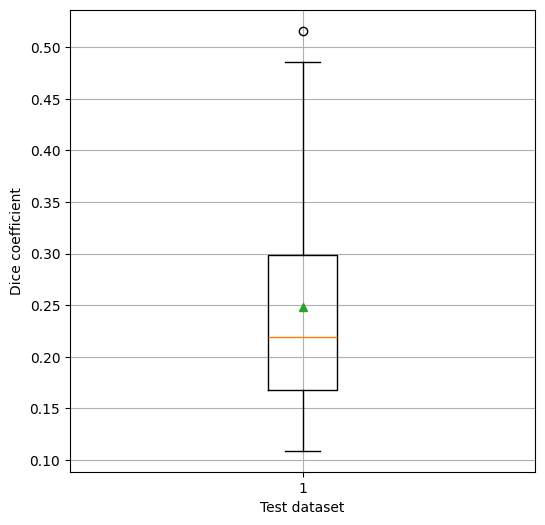

In [47]:
nb_classes = 8

def DiceCoeff(y_true, y_pred):

    dice = np.zeros(nb_classes)

    for i in range(nb_classes):

        y_true_bin = y_true[:,:,i]
        y_pred_bin = np.round(y_pred[:,:,i])

        intersection = np.sum(y_true_bin * y_pred_bin)
        denom = np.sum(y_true_bin) + np.sum(y_pred_bin)

        if denom == 0:
            dice[i] = 1
        else:
            dice[i] = 2 * intersection / denom

    return np.mean(dice)


dc_all = np.zeros(pred_masks.shape[0])

for i in range(pred_masks.shape[0]):
    dc_all[i] = DiceCoeff(test_labels1[i], pred_masks[i])

print("Mean Dice:", np.mean(dc_all))
print("Std Dice:", np.std(dc_all))

plt.figure(figsize=(6,6))
plt.boxplot(dc_all, showmeans=True)
plt.grid(True)
plt.ylabel('Dice coefficient')
plt.xlabel('Test dataset')
plt.show()

In [48]:
# @interact(x=(0, len(label_data)-1, 1))
# def h(x=0):

#     f = plt.figure(figsize=(12,6))

#     # Ground truth
#     f.add_subplot(1,2,1)
#     gt = process_label(np.argmax(label_data2[x], axis=2) + 1)
#     plt.imshow(gt)
#     plt.title("Ground Truth")
#     plt.axis("off")

#     # Reconstruction
#     f.add_subplot(1,2,2)
#     #pred = process_label(np.argmax(label_data[x], axis=2) + 1)
#     mask = np.argmax(pred_masks[x], axis=2)
#     pred = process_label(mask + 1)
#     plt.imshow(pred)
#     plt.title("Reconstructed Mask")
#     plt.axis("off")

#     plt.show()

label_data = pred_masks
label_data2 = test_labels1

@interact(x=(0, len(label_data)-1, 1))
def h(x=0):

    f = plt.figure(figsize=(12,6))

    # Ground truth
    f.add_subplot(1,2,1)

    gt_mask = np.argmax(label_data2[x], axis=-1)
    gt = process_label(gt_mask)

    plt.imshow(gt)
    plt.title("Ground Truth")
    plt.axis("off")

    # Prediction
    f.add_subplot(1,2,2)

    pred_mask = np.argmax(label_data[x], axis=-1)
    pred = process_label(pred_mask)

    plt.imshow(pred)
    plt.title("Reconstructed Mask")
    plt.axis("off")

    plt.show()

interactive(children=(IntSlider(value=0, description='x', max=26), Output()), _dom_classes=('widget-interact',…

### Create datasets for dimension reduction and diagnosis

### UMAP for important feature analysis

In [49]:
# model.summary()


In [81]:
encoder = model.get_layer("encoder")
latent_vectors = encoder.predict(training_gen, steps=steps_epoch)
# print(latent_vectors.shape)



80/80 ━━━━━━━━━━━━━━━━━━━━ 10s 108ms/step


In [87]:
latent_list = []
label_list = []

for x_batch, y_batch in training_gen.take(
        int(np.ceil(200 / train_mini_batch_sz))):

    z_batch = encoder.predict(x_batch, verbose=0)
    bottleneck_batch = z_batch[-1]

    latent_list.append(bottleneck_batch)
    label_list.append(y_batch[1])

latent_vectors = np.concatenate(latent_list, axis=0)[:51]
labels = np.concatenate(label_list, axis=0)[:51]

labels = np.argmax(labels, axis=1)
latent_vectors = latent_vectors.reshape(latent_vectors.shape[0], -1)

print(latent_vectors.shape)
print(labels.shape)



(51, 18)
(51,)


2026-03-13 17:07:27.237622: I tensorflow/core/framework/local_rendezvous.cc:405] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence


In [83]:
# latent_scaled = StandardScaler().fit_transform(latent_vectors)
# embedding = umap.UMAP(
#     n_neighbors=6,
#     min_dist=0.0,
#     random_state=42
# ).fit_transform(latent_scaled)

In [84]:
# print(embedding.shape)
# print(labels.shape)

In [85]:
# print(np.unique(labels))

# plt.figure(figsize=(6,6))

# for class_id, color, name in zip([0,1], ['blue','red'], ['Healthy','Glaucoma']):
#     idx = labels == class_id
#     plt.scatter(embedding[idx,0], embedding[idx,1], s=8, color=color, label=name)

# plt.legend()
# plt.show()

In [88]:
X_train_latent, X_test_latent, y_train, y_test = train_test_split(
    latent_vectors,
    labels,
    test_size=0.2,
    stratify=labels,
    random_state=42
)

In [89]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train_latent)
X_test_scaled = scaler.transform(X_test_latent)

In [90]:
# reducer = umap.UMAP(
#     n_neighbors=6,
#     min_dist=0.0,
#     n_components=2,
#     random_state=42
# )

# X_train_umap = reducer.fit_transform(X_train_scaled)
# X_test_umap = reducer.transform(X_test_scaled)

# # reducer = umap.UMAP(
# #     n_neighbors=6,
# #     min_dist=0.0,
# #     n_components=5,
# #     random_state=42
# # )

# # X_train_umap = reducer.fit_transform(X_train_scaled, y_train)
# # X_test_umap  = reducer.transform(X_test_scaled)

In [74]:
# scores = cross_val_score(
#     clf,
#     reducer.fit_transform(latent_scaled),  # small dataset acceptable here
#     labels,
#     cv=5
# )

# print("CV Accuracy:", np.mean(scores))

In [56]:
# plt.figure(figsize=(6,6))

# for label in np.unique(labels):
#     idx = labels == label
#     plt.scatter(
#         embedding[idx, 0],
#         embedding[idx, 1],
#         label=f"Class {label}",
#         alpha=0.7
#     )

# plt.legend()
# plt.title("UMAP Embedding")
# plt.show()

In [91]:
X_train_scaled = scaler.fit_transform(X_train_latent)
X_test_scaled  = scaler.transform(X_test_latent)

In [67]:
pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('umap', umap.UMAP(
        n_components=3,
        n_neighbors=10,
        min_dist=0.1,
        target_weight=0.7,
        random_state=42
    )),
    ('svm', SVC(kernel='rbf', C=10, gamma=0.01))
])

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

scores = cross_val_score(pipeline, latent_vectors, labels, cv=cv)

print("CV Accuracy:", scores.mean())
print("Std:", scores.std())

/home/suraj/Suraj_env/lib/python3.10/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
/home/suraj/Suraj_env/lib/python3.10/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
/home/suraj/Suraj_env/lib/python3.10/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
/home/suraj/Suraj_env/lib/python3.10/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
/home/suraj/Suraj_env/lib/python3.10/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


CV Accuracy: 0.8150000000000001
Std: 0.040620192023179784


In [75]:
# clf = Pipeline([
#     ('scaler', StandardScaler()),
#     ('svm', SVC(kernel='rbf', C=1, gamma='scale'))
# ])

# cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# scores = cross_val_score(clf, latent_vectors, labels, cv=cv)

# print("CV Accuracy:", scores.mean())

clf = Pipeline([
    ('scaler', StandardScaler()),
    ('umap', umap.UMAP(
        n_components=10,
        n_neighbors=10,
        min_dist=0.1,
        target_weight=0.7,
        random_state=42
    )),
    ('rf', RandomForestClassifier(
        n_estimators=200,
        max_depth=None,
        random_state=42
    ))
])

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

scores = cross_val_score(clf, latent_vectors, labels, cv=cv)

print("CV Accuracy:", scores.mean())
print("Std:", scores.std())

/home/suraj/Suraj_env/lib/python3.10/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
/home/suraj/Suraj_env/lib/python3.10/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
/home/suraj/Suraj_env/lib/python3.10/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
/home/suraj/Suraj_env/lib/python3.10/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
/home/suraj/Suraj_env/lib/python3.10/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


CV Accuracy: 0.8150000000000001
Std: 0.058309518948453015


In [208]:
param_grid = {
    'svm__C': [0.1, 1, 10, 50],
    'svm__gamma': ['scale', 0.1, 0.01]
}

grid = GridSearchCV(clf, param_grid, cv=cv)
grid.fit(latent_vectors, labels)

print("Best CV Accuracy:", grid.best_score_)
print("Best Params:", grid.best_params_)

Best CV Accuracy: 0.8799999999999999
Best Params: {'svm__C': 10, 'svm__gamma': 0.01}


In [209]:
print(scores)
print("Mean:", scores.mean())
print("Std:", scores.std())

[0.875 0.75  0.85  0.925 0.85 ]
Mean: 0.85
Std: 0.05700877125495691


In [211]:
y_pred = cross_val_predict(clf, latent_vectors, labels, cv=cv)

print(classification_report(labels, y_pred))

              precision    recall  f1-score   support

           0       0.87      0.82      0.84        98
           1       0.83      0.88      0.86       102

    accuracy                           0.85       200
   macro avg       0.85      0.85      0.85       200
weighted avg       0.85      0.85      0.85       200



In [212]:
y_prob = cross_val_predict(clf, latent_vectors, labels, cv=cv, method='decision_function')
print("AUC:", roc_auc_score(labels, y_prob))

AUC: 0.9289715886354543


In [214]:
# Get decision scores (cross-validated)
y_scores = cross_val_predict(
    clf,
    latent_vectors,
    labels,
    cv=cv,
    method='decision_function'
)

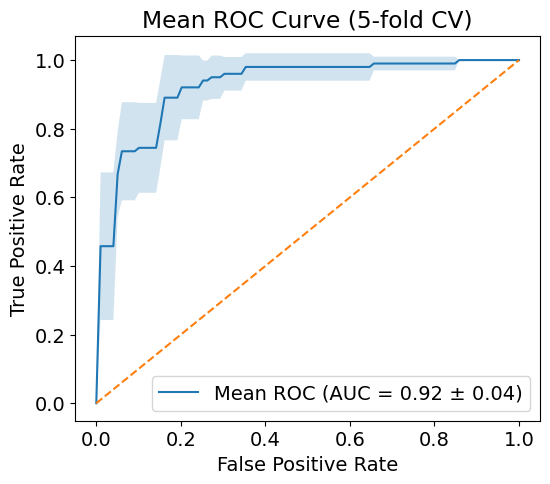

Mean ROC AUC: 0.923954887218045
Std ROC AUC: 0.03523947878188166


In [219]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

tprs = []
aucs = []
mean_fpr = np.linspace(0, 1, 100)

for train_idx, test_idx in cv.split(latent_vectors, labels):
    
    clf.fit(latent_vectors[train_idx], labels[train_idx])
    y_score = clf.decision_function(latent_vectors[test_idx])
    
    fpr, tpr, _ = roc_curve(labels[test_idx], y_score)
    roc_auc = auc(fpr, tpr)
    
    aucs.append(roc_auc)
    tprs.append(np.interp(mean_fpr, fpr, tpr))
    tprs[-1][0] = 0.0

mean_tpr = np.mean(tprs, axis=0)
std_tpr = np.std(tprs, axis=0)
mean_auc = np.mean(aucs)
std_auc = np.std(aucs)

plt.figure(figsize=(6,5))
plt.plot(mean_fpr, mean_tpr,
         label=f"Mean ROC (AUC = {mean_auc:.2f} ± {std_auc:.2f})")

plt.fill_between(mean_fpr,
                 mean_tpr - std_tpr,
                 mean_tpr + std_tpr,
                 alpha=0.2)

plt.plot([0, 1], [0, 1], linestyle='--')
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Mean ROC Curve (5-fold CV)")
plt.legend()
plt.show()

print("Mean ROC AUC:", mean_auc)
print("Std ROC AUC:", std_auc)

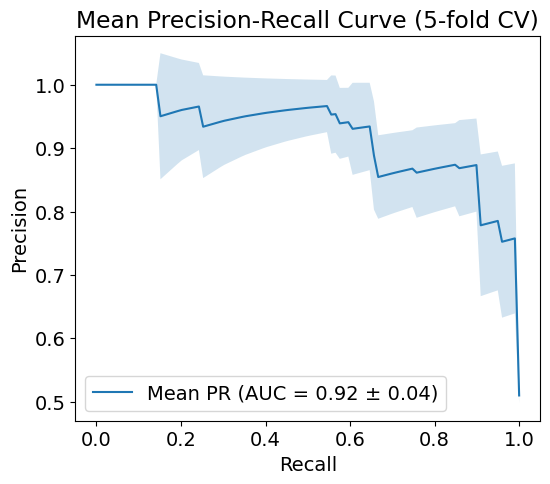

Mean PR AUC: 0.9196894789122545
Std PR AUC: 0.03529021044680977


In [221]:
precisions = []
pr_aucs = []
mean_recall = np.linspace(0, 1, 100)

for train_idx, test_idx in cv.split(latent_vectors, labels):
    
    clf.fit(latent_vectors[train_idx], labels[train_idx])
    y_score = clf.decision_function(latent_vectors[test_idx])
    
    precision, recall, _ = precision_recall_curve(labels[test_idx], y_score)
    pr_auc = auc(recall, precision)
    
    pr_aucs.append(pr_auc)
    precisions.append(np.interp(mean_recall, recall[::-1], precision[::-1]))

mean_precision = np.mean(precisions, axis=0)
std_precision = np.std(precisions, axis=0)
mean_pr_auc = np.mean(pr_aucs)
std_pr_auc = np.std(pr_aucs)

plt.figure(figsize=(6,5))
plt.plot(mean_recall, mean_precision,
         label=f"Mean PR (AUC = {mean_pr_auc:.2f} ± {std_pr_auc:.2f})")

plt.fill_between(mean_recall,
                 mean_precision - std_precision,
                 mean_precision + std_precision,
                 alpha=0.2)

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Mean Precision-Recall Curve (5-fold CV)")
plt.legend()
plt.show()

print("Mean PR AUC:", mean_pr_auc)
print("Std PR AUC:", std_pr_auc)

### Principal Component Analysis

In [92]:
encoder_latent = Model(
    inputs=encoder.input,
    outputs=encoder.output[6]
)

# Predict latent features
latent_output = encoder_latent.predict(train_images1)

print("Latent shape:", latent_output.shape)

train_output_flat = latent_output.reshape(latent_output.shape[0], -1)

print("Flattened shape:", train_output_flat.shape)

IndexError: list index out of range

### Classification with 54 latent features

In [54]:
clf = Pipeline([
    ('scaler', StandardScaler()),
    ('svm', SVC(kernel='rbf', probability=True))
])
labels = np.argmax(train_diag1, axis=1)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

scores = cross_val_score(clf, train_output_flat, labels, cv=cv)

print("Mean CV Accuracy:", scores.mean())
print("Std Dev:", scores.std())

Mean CV Accuracy: 0.8428571428571429
Std Dev: 0.08017837257372733


In [55]:
# # Binary labels
# y = np.argmax(train_diag1, axis=1)

# # Classifier
# clf = Pipeline([
#     ('scaler', StandardScaler()),
#     ('svm', SVC(kernel='rbf', probability=True))
# ])

# cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# mean_fpr = np.linspace(0, 1, 200)
# tprs = []
# aucs = []

# plt.figure(figsize=(6,6))

# for train_idx, test_idx in cv.split(train_output_flat, y):

#     X_train, X_test = train_output_flat[train_idx], train_output_flat[test_idx]
#     y_train, y_test = y[train_idx], y[test_idx]

#     clf.fit(X_train, y_train)
#     y_proba = clf.predict_proba(X_test)[:,1]

#     fpr, tpr, _ = roc_curve(y_test, y_proba)
#     roc_auc = auc(fpr, tpr)

#     aucs.append(roc_auc)

#     interp_tpr = np.interp(mean_fpr, fpr, tpr)
#     interp_tpr[0] = 0.0
#     tprs.append(interp_tpr)

# # ---- Compute Mean & SD ----
# mean_tpr = np.mean(tprs, axis=0)
# std_tpr  = np.std(tprs, axis=0)

# mean_tpr[-1] = 1.0

# mean_auc = np.mean(aucs)
# std_auc  = np.std(aucs)

# # ---- Plot Mean ROC ----
# plt.plot(mean_fpr, mean_tpr,
#          color='black',
#          label=f'Mean ROC (AUC = {mean_auc:.3f} ± {std_auc:.3f})')

# # ---- Plot ±1 SD Shading ----
# tpr_upper = np.minimum(mean_tpr + std_tpr, 1)
# tpr_lower = np.maximum(mean_tpr - std_tpr, 0)

# plt.fill_between(mean_fpr,
#                  tpr_lower,
#                  tpr_upper,
#                  alpha=0.2
#                  )

# plt.plot([0,1],[0,1],color='black',linestyle='--')

# plt.xlabel('False Positive Rate', fontsize=14)
# plt.ylabel('True Positive Rate', fontsize=14)
# #plt.title('ROC Curve', fontsize=14)

# plt.legend(loc='lower right')
# plt.grid(False)
# plt.show()

# print(f"Mean AUC: {mean_auc:.4f}")
# print(f"Std AUC : {std_auc:.4f}")

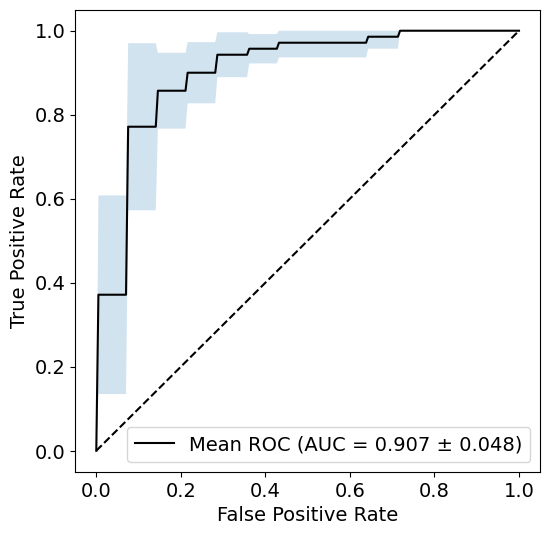

Mean AUC: 0.9071
Std AUC : 0.0481


In [56]:
# Binary labels
y = np.argmax(train_diag1, axis=1)

# ---- MLP Classifier ----
clf = Pipeline([
    ('scaler', StandardScaler()),
    ('mlp', MLPClassifier(hidden_layer_sizes=(100,),
                          activation='relu',
                          solver='adam',
                          max_iter=500,
                          random_state=42))
])

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

mean_fpr = np.linspace(0, 1, 200)
tprs = []
aucs = []

plt.figure(figsize=(6,6))

for train_idx, test_idx in cv.split(train_output_flat, y):

    X_train, X_test = train_output_flat[train_idx], train_output_flat[test_idx]
    y_train, y_test = y[train_idx], y[test_idx]

    clf.fit(X_train, y_train)
    y_proba = clf.predict_proba(X_test)[:,1]

    fpr, tpr, _ = roc_curve(y_test, y_proba)
    roc_auc = auc(fpr, tpr)

    aucs.append(roc_auc)

    interp_tpr = np.interp(mean_fpr, fpr, tpr)
    interp_tpr[0] = 0.0
    tprs.append(interp_tpr)

# ---- Compute Mean & SD ----
mean_tpr = np.mean(tprs, axis=0)
std_tpr  = np.std(tprs, axis=0)

mean_tpr[-1] = 1.0

mean_auc = np.mean(aucs)
std_auc  = np.std(aucs)

# ---- Plot Mean ROC ----
plt.plot(mean_fpr, mean_tpr,
         color='black',
         label=f'Mean ROC (AUC = {mean_auc:.3f} ± {std_auc:.3f})')

# ---- Plot ±1 SD Shading ----
tpr_upper = np.minimum(mean_tpr + std_tpr, 1)
tpr_lower = np.maximum(mean_tpr - std_tpr, 0)

plt.fill_between(mean_fpr,
                 tpr_lower,
                 tpr_upper,
                 alpha=0.2)

plt.plot([0,1],[0,1],color='black',linestyle='--')

plt.xlabel('False Positive Rate', fontsize=14)
plt.ylabel('True Positive Rate', fontsize=14)

plt.legend(loc='lower right')
plt.grid(False)
plt.show()

print(f"Mean AUC: {mean_auc:.4f}")
print(f"Std AUC : {std_auc:.4f}")

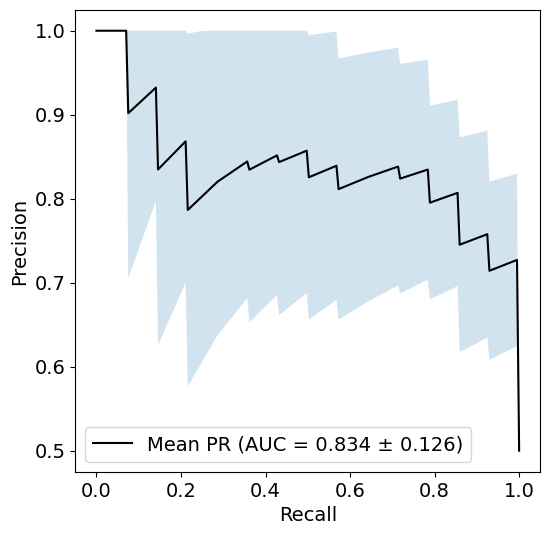

Mean PR AUC: 0.8345
Std PR AUC : 0.1259


In [57]:
# Binary labels
y = np.argmax(train_diag1, axis=1)

# ---- MLP Classifier ----
clf = Pipeline([
    ('scaler', StandardScaler()),
    ('mlp', MLPClassifier(hidden_layer_sizes=(128,64),
                          activation='relu',
                          solver='adam',
                          alpha=0.001,
                          max_iter=500,
                          early_stopping=True,
                          random_state=42))
])

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

mean_recall = np.linspace(0, 1, 200)
precisions = []
pr_aucs = []

plt.figure(figsize=(6,6))

for train_idx, test_idx in cv.split(train_output_flat, y):

    X_train, X_test = train_output_flat[train_idx], train_output_flat[test_idx]
    y_train, y_test = y[train_idx], y[test_idx]

    clf.fit(X_train, y_train)
    y_proba = clf.predict_proba(X_test)[:,1]

    precision, recall, _ = precision_recall_curve(y_test, y_proba)

    # PR AUC
    pr_auc = auc(recall, precision)
    pr_aucs.append(pr_auc)

    # Interpolation (reverse recall because it decreases)
    precision_interp = np.interp(mean_recall, recall[::-1], precision[::-1])
    precisions.append(precision_interp)

# ---- Compute Mean & SD ----
mean_precision = np.mean(precisions, axis=0)
std_precision  = np.std(precisions, axis=0)

mean_pr_auc = np.mean(pr_aucs)
std_pr_auc  = np.std(pr_aucs)

# ---- Plot Mean PR ----
plt.plot(mean_recall, mean_precision,
         color='black',
         label=f'Mean PR (AUC = {mean_pr_auc:.3f} ± {std_pr_auc:.3f})')

# ---- ±1 SD shading ----
precision_upper = np.minimum(mean_precision + std_precision, 1)
precision_lower = np.maximum(mean_precision - std_precision, 0)

plt.fill_between(mean_recall,
                 precision_lower,
                 precision_upper,
                 alpha=0.2)

# # Baseline (positive prevalence)
# baseline = np.mean(y)
# plt.hlines(baseline, 0, 1, linestyles='--', color='black')

plt.xlabel('Recall', fontsize=14)
plt.ylabel('Precision', fontsize=14)
plt.legend(loc='lower left')
plt.grid(False)
plt.show()

print(f"Mean PR AUC: {mean_pr_auc:.4f}")
print(f"Std PR AUC : {std_pr_auc:.4f}")

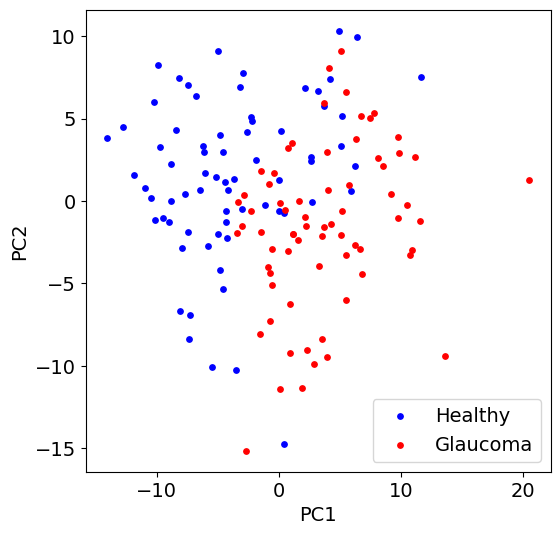

In [67]:
# PCA
pca_2 = PCA(n_components=2)
latent_2d = pca_2.fit_transform(train_output_flat)

# Separate indices
healthy_idx = labels == 0
glaucoma_idx = labels == 1

plt.figure(figsize=(6,6))

# Healthy (blue)
plt.scatter(latent_2d[healthy_idx, 0],
            latent_2d[healthy_idx, 1],
            color='blue',
            s=15,        # small dots
            label='Healthy')

# Glaucoma (red)
plt.scatter(latent_2d[glaucoma_idx, 0],
            latent_2d[glaucoma_idx, 1],
            color='red',
            s=15,
            label='Glaucoma')

plt.xlabel('PC1', fontsize=14)
plt.ylabel('PC2', fontsize=14)
#plt.title('PCA of Latent Space', fontsize=14)

plt.legend()
plt.grid(False)
plt.show()

### Classification with PC1 and PC2

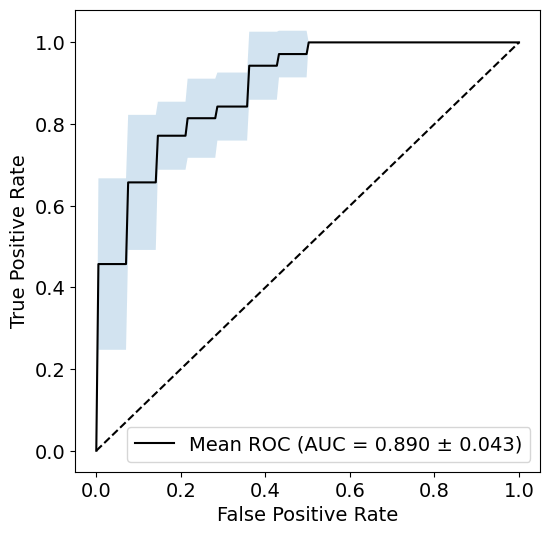

Mean AUC: 0.889795918367347
Std AUC: 0.043364345634440325


In [70]:
# Define pipeline
pipeline = Pipeline([
    ('pca', PCA(n_components=2)),
    ('svm', SVC(kernel='rbf', probability=True))
])

# Stratified 5-fold
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# For mean ROC
mean_fpr = np.linspace(0, 1, 200)
tprs = []
aucs = []

plt.figure(figsize=(6,6))

for train_index, test_index in skf.split(train_output_flat, labels):
    
    X_train, X_test = train_output_flat[train_index], train_output_flat[test_index]
    y_train, y_test = labels[train_index], labels[test_index]
    
    pipeline.fit(X_train, y_train)
    
    y_prob = pipeline.predict_proba(X_test)[:, 1]
    
    fpr, tpr, _ = roc_curve(y_test, y_prob)
    roc_auc = auc(fpr, tpr)
    
    aucs.append(roc_auc)
    
    # Interpolate
    interp_tpr = np.interp(mean_fpr, fpr, tpr)
    interp_tpr[0] = 0.0
    tprs.append(interp_tpr)

# Compute mean and std
mean_tpr = np.mean(tprs, axis=0)
std_tpr = np.std(tprs, axis=0)

mean_auc = np.mean(aucs)
std_auc = np.std(aucs)

mean_tpr[-1] = 1.0

# Plot mean ROC
plt.plot(mean_fpr, mean_tpr,
         color = 'black',
         label=f'Mean ROC (AUC = {mean_auc:.3f} ± {std_auc:.3f})'
         )

# Shade ±1 SD
plt.fill_between(mean_fpr,
                 mean_tpr - std_tpr,
                 mean_tpr + std_tpr,
                 alpha=0.2)

plt.plot([0,1], [0,1], color = 'black', linestyle='--')

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
#plt.title("ROC Curve (PCA + SVM)")
plt.legend(loc="lower right")
plt.grid(False)
plt.show()

print("Mean AUC:", mean_auc)
print("Std AUC:", std_auc)

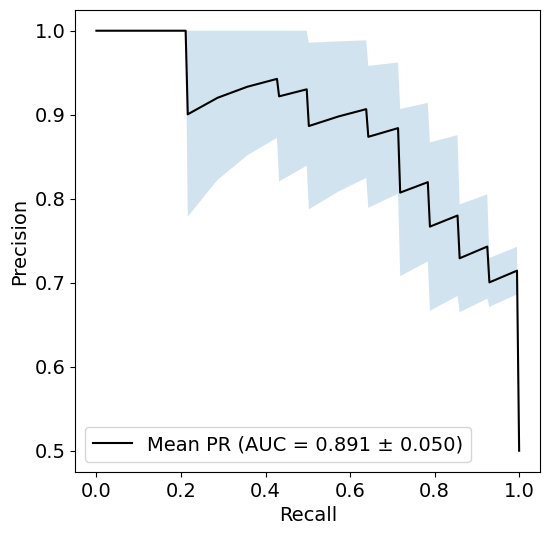

Mean AP: 0.8911350763468189
Std AP: 0.050165478675970404


In [72]:
# Define pipeline
pipeline = Pipeline([
    ('pca', PCA(n_components=2)),
    ('svm', SVC(kernel='rbf', probability=True))
])

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

mean_recall = np.linspace(0, 1, 200)

precisions = []
aps = []

plt.figure(figsize=(6,6))

for train_index, test_index in skf.split(train_output_flat, labels):
    
    X_train, X_test = train_output_flat[train_index], train_output_flat[test_index]
    y_train, y_test = labels[train_index], labels[test_index]
    
    pipeline.fit(X_train, y_train)
    
    y_prob = pipeline.predict_proba(X_test)[:, 1]
    
    precision, recall, _ = precision_recall_curve(y_test, y_prob)
    ap = average_precision_score(y_test, y_prob)
    
    aps.append(ap)
    
    # Reverse arrays (recall is descending sometimes)
    precision = precision[::-1]
    recall = recall[::-1]
    
    interp_precision = np.interp(mean_recall, recall, precision)
    precisions.append(interp_precision)

# Compute mean and std
mean_precision = np.mean(precisions, axis=0)
std_precision = np.std(precisions, axis=0)

mean_ap = np.mean(aps)
std_ap = np.std(aps)

# Clip to valid range
upper = np.clip(mean_precision + std_precision, 0, 1)
lower = np.clip(mean_precision - std_precision, 0, 1)

# Plot mean PR curve
plt.plot(mean_recall, mean_precision,
         color = 'black',
         label=f'Mean PR (AUC = {mean_ap:.3f} ± {std_ap:.3f})'
         )

plt.fill_between(mean_recall, lower, upper, alpha=0.2)

plt.xlabel("Recall")
plt.ylabel("Precision")
#plt.title("Precision–Recall Curve (PCA + SVM)")
plt.legend(loc="lower left")
plt.grid(False)
plt.show()

print("Mean AP:", mean_ap)
print("Std AP:", std_ap)

In [70]:
# #print(explained_variance_ratio_)
# f = plt.figure(figsize=(6,6))
# plt.rcParams.update({'font.size': 14})
# plt.scatter(pca_numcomp_result[:,0], pca_numcomp_result[:,2], c=train_ids_forplotting, s=5, cmap='tab10')


In [69]:
# ae_covmat = np.round(np.cov(train_output_flat.T), 2)
# print('Autoencoder components')
# print(ae_covmat[0:10,0:10])

# pca_covmat = np.round(np.cov(pca_numcomp_result.T), 2)
# print('PCA components')
# print(pca_covmat[0:10,0:10])

### UMAP embedding

In [60]:
# UMAPembedding = umap.UMAP(n_components=2, random_state=0).fit(pca_numcomp_result)
# print(np.shape(UMAPembedding.embedding_))

In [48]:
# f = plt.figure(figsize=(9,6))
# plt.rcParams.update({'font.size': 16})
# plt.scatter(UMAPembedding.embedding_[:, 0], UMAPembedding.embedding_[:,1], 
#             c=train_ids_forplotting,s=5)
# plt.xlabel('Latent Dimension 1')
# plt.ylabel('Latent Dimension 2')
# plt.title('UMAP embedding with {} latent features'.format(numcomp))
# plt.savefig('./UMAP_clustering_'+str(numcomp)+'.png')

In [49]:
# corners = np.array([[0, 7],  # 1
#                     [10, 7],  # 7
#                     [0, 4],
#                     [10, 4]])

# NumPoints = 5
# test_pts = np.array([ (corners[0]*(1-x) + corners[1]*x)*(1-y) 
#                      + (corners[2]*(1-x) + corners[3]*x)*y
#                         for y in np.linspace(0, 1, NumPoints)
#                         for x in np.linspace(0, 1, NumPoints) ])

# inv_transformed_points1 = UMAPembedding.inverse_transform(test_pts)
# inv_transformed_points = pca_numcomp.inverse_transform(inv_transformed_points1)
# print(np.shape(inv_transformed_points))


In [50]:
# # Set up the grid
# fig= plt.figure(figsize=(18,6))
# gs = GridSpec(NumPoints, 2*NumPoints, fig)
# scatter_ax = fig.add_subplot(gs[:, :NumPoints])
# digit_axes = np.zeros((NumPoints, NumPoints), dtype=object)
# for i in range(NumPoints):
#     for j in range(NumPoints):
#         digit_axes[i, j] = fig.add_subplot(gs[i, NumPoints + j])

# # Use umap.plot to plot to the major axis
# scatter_ax.set_facecolor((0.6,0.6,0.6))
# scatter_ax.scatter(UMAPembedding.embedding_[:, 0], UMAPembedding.embedding_[:, 1],
#                    c=train_ids_forplotting, s=5)
# scatter_ax.set(xticks=[], yticks=[])

# # Plot the locations of the text points
# scatter_ax.scatter(test_pts[:, 0], test_pts[:, 1], marker='x', c='w', s=155)

# # Plot each of the generated digit images
# for i in range(NumPoints):
#     for j in range(NumPoints):
#         temp_Xtrue = np.reshape(inv_transformed_points[i*NumPoints + j],(1, 3,3,NumLyrLtnSpc))
#         x_decoded_all = decoder.predict(temp_Xtrue)
#         x_decoded = x_decoded_all[0]
#         color_label= HFObj.process_label(np.argmax(x_decoded[0,:,:,:], axis=2)+1)
#         digit_axes[i, j].imshow(color_label)
#         digit_axes[i, j].set(xticks=[], yticks=[])

# # plt.savefig('./UMAP_ArrayReconImages'+str(numcomp)+'.png')

In [51]:
# def plot_embedding(X_embedded,X_label, title=None, plotimageoncanvas = False):
#     X = X_embedded
#     x_min, x_max = np.min(X, 0), np.max(X, 0)
#     X = (X - x_min) / (x_max - x_min)
    
#     f = plt.figure(figsize=(18,12))
#     ax = plt.subplot(111)
#     plt.scatter(X[:, 0], X[:, 1], c=X_label,s=5)
    
    
#     if hasattr(offsetbox, 'AnnotationBbox') and plotimageoncanvas == True:
#         # only print thumbnails with matplotlib > 1.0
#         shown_images = np.array([[1., 1.]])  # just something big
#         for i in range(X.shape[0]):
#             dist = np.sum((X[i] - shown_images) ** 2, 1)
#             if np.min(dist) < 3e-2:
#                 # don't show points that are too close
#                 continue
#             shown_images = np.r_[shown_images, [X[i]]]
            
            
#             inv_transformed_points1 = \
#                 UMAPembedding.inverse_transform(np.reshape(X_embedded[i],(1,2)))
#             X_true = pca_numcomp.inverse_transform(inv_transformed_points1)
#             temp_Xtrue = np.reshape(X_true,(1, 3,3,NumLyrLtnSpc))
#             x_decoded_all = decoder.predict(temp_Xtrue)
#             x_decoded = x_decoded_all[0]
#             color_label= HFObj.process_label(np.argmax(x_decoded[0,:,:,:], axis=2)+1)
            
#             imagebox = offsetbox.AnnotationBbox(
#                 offsetbox.OffsetImage(color_label,zoom=0.25),
#                 X[i])
#             ax.add_artist(imagebox)
            
#     plt.savefig('./UMAP_OverlapReconImages'+str(numcomp)+'.png')

In [52]:
# plot_embedding(UMAPembedding.embedding_,train_ids_forplotting,plotimageoncanvas = True)

### generate movie for PCs

In [53]:
# ### RNFL 
# def LayerInspection(img_label,numpixels):
#     img_copy = np.copy(img_label)
#     if numpixels > 0 :
#         for j in range(400):
#             for i in range(200):
#                 if img_label[i,j] == 2:
#                     img_copy[i:i+numpixels,j] = 1
#                     break

#     return img_copy


# def RNFLInspection(img_label,numpixels):
#     img_copy = np.copy(img_label)
#     if numpixels > 0 :
#         for j in range(400):
#             for i in range(200):
#                 if img_label[i,j] == 2:
#                     img_copy[i:i+numpixels,j] = 1
#                     break

#     return img_copy

# def GCCInspection(img_label,numpixels):
#     img_copy = np.copy(img_label)
#     if numpixels > 0 :
#         for j in range(400):
#             for i in range(200):
#                 if img_label[i,j] == 3:
#                     img_copy[i:i+numpixels,j] = 2
#                     break

#     return img_copy

# def OtherInspection(img_label,numpixels):
#     img_copy = np.copy(img_label)
#     if numpixels > 0 :
#         for j in range(400):
#             for i in range(200):
#                 if img_label[i,j] == 4:
#                     img_copy[i:i+numpixels,j] = 3
#                     break

#     return img_copy


In [54]:
# # 1084   772

# index = 1084
# #input image
# input_image = test_images[index:index+1,:,:,:]
# # input label
# input_label1 = (test_labels[index:index+1,:,:,:])[0]
# input_label = np.argmax(input_label1, axis=2)+1
# color_label_input = HFObj.process_label(input_label)
# # reduce to latent space
# tout = encoder.predict(input_image)
# tout1 = np.array(tout.flatten())
# tout2 = np.copy(np.expand_dims(tout1, axis=0))

# ### reconstruction by autoencoder
# reconimg,t111 = decoder.predict(np.reshape(tout2,(1, 3,3,NumLyrLtnSpc)))
# reconimg_label= HFObj.process_label(np.argmax(reconimg[0,:,:,:], axis=2)+1)


# changeindex=0

# tout2_umap_array=np.array([[1,1]])

# numsteps = 5
# for x in range(numsteps):
#     tout2_pca = pca_numcomp.transform(tout2)

#     base_value = tout2_pca[0,changeindex]
#     maginify = 3
#     dev_value = base_value*maginify
#     new_value = (base_value) - (dev_value)/numsteps*x
#     print(new_value)
    
#     tout2_pca1 = np.copy(tout2_pca)
#     tout2_pca1[0,changeindex] = new_value
# #     print(tout2_pca1)

#     tout2_invpca = pca_numcomp.inverse_transform(tout2_pca1)
#     tout2_umap = UMAPembedding.transform(tout2_pca1)
#     tout2_umap_array = np.append(tout2_umap_array,tout2_umap,axis=0)

#     tout2_invpca1 = np.reshape(tout2_invpca,(1, 3,3,NumLyrLtnSpc))
#     tout2_reconimg,t111 = decoder.predict(tout2_invpca1)
    
#     img_label = np.argmax(tout2_reconimg[0,:,:,:], axis=2)+1
#     img_label = LayerInspection(img_label,x-18)
#     color_label= HFObj.process_label(img_label)
    
#     if x == 0 or x ==numsteps-1:
# #         np.save('./Movie/img_label_'+str(x)+'.npy',img_label)
#         (Image.fromarray(color_label)).save('./Movie/img_label_'+str(x)+'.png')
#         (Image.fromarray(color_label_input)).save('./Movie/input_img.png')
    
        
    

#     f = plt.figure(figsize=(12,6))
#     plt.rcParams.update({'font.size': 10})
#     sp = f.add_subplot(2, 2, 1)
#     plt.imshow(color_label_input)
#     plt.title('Input image to the encoder')
# #     g1 = sp.grid(b=True, which='major', color='r', linestyle='-', linewidth=0.5)
# #     g2 = sp.grid(b=True, which='minor', color='r', linestyle='-', linewidth=0.25)
# #     sp.minorticks_on()
    
#     sp = f.add_subplot(2, 2, 2)
#     plt.imshow(reconimg_label)
#     plt.title('Reconstructed image by the decoder')
# #     g1 = sp.grid(b=True, which='major', color='r', linestyle='-', linewidth=0.5)
# #     g2 = sp.grid(b=True, which='minor', color='r', linestyle='-', linewidth=0.25)
# #     sp.minorticks_on()
    
#     sp = f.add_subplot(2, 2, 3)
#     plt.imshow(color_label)
#     plt.title('Reconstructed image by varying PC {} '.format(changeindex))
# #     g1 = sp.grid(b=True, which='major', color='r', linestyle='-', linewidth=0.5)
# #     g2 = sp.grid(b=True, which='minor', color='r', linestyle='-', linewidth=0.25)
# #     sp.minorticks_on()
    
#     sp = f.add_subplot(2, 2, 4)    
#     plt.scatter(UMAPembedding.embedding_[:, 0], UMAPembedding.embedding_[:,1],s=1, c=train_ids_forplotting)
# #     plt.scatter(tout2_umap_array[1:, 0], tout2_umap_array[1:, 1], marker='x', c='k', s=225)
#     plt.plot(tout2_umap_array[1:, 0], tout2_umap_array[1:, 1], 'k-*')
#     plt.title('Transition of non-goaucomatous ONH in UMAP latent space')
#     plt.savefig('./Movie/'+str(x) +'.png')
    

    
# images=[]
# for i in range(numsteps):
#     images.append(imageio.imread('./Movie/'+str(i)+'.png'))
    

# imageio.mimsave('./Movie/'+str(numcomp)+'_comp_movie_p'+str(changeindex)+'.gif', images, duration=0.25)

In [55]:
# print(np.shape(UMAPembedding.embedding_))
# umap_covmat = np.round(np.cov(UMAPembedding.embedding_.T), 2)
# print('UMAP components')
# print(umap_covmat)

In [56]:
# # 1084   772

# index = 1084

# #input image
# input_image = test_images[index:index+1,:,:,:]

# # input label
# input_label1 = (test_labels[index:index+1,:,:,:])[0]
# input_label = np.argmax(input_label1, axis=2)+1
# color_label_input = HFObj.process_label(input_label)

# # reduce to latent space
# tout = encoder.predict(input_image)
# tout1 = np.array(tout.flatten())
# tout2 = np.copy(np.expand_dims(tout1, axis=0))

# ### reconstruction by autoencoder
# reconimg,t111 = decoder.predict(np.reshape(tout2,(1, 3,3,NumLyrLtnSpc)))
# reconimg_label= HFObj.process_label(np.argmax(reconimg[0,:,:,:], axis=2)+1)


# changeindex=0

# tout2_umap_array=np.array([[1,1]])

# numsteps = 5
# for x in range(numsteps):
#     tout2_pca = pca_numcomp.transform(tout2)

#     base_value = tout2_pca[0,changeindex]
#     maginify = 3
#     dev_value = base_value*maginify
#     new_value = (base_value) - (dev_value)/numsteps*x
#     print(new_value)
    
#     tout2_pca1 = np.copy(tout2_pca)
#     tout2_pca1[0,changeindex] = new_value
# #     print(tout2_pca1)

#     tout2_invpca = pca_numcomp.inverse_transform(tout2_pca1)
#     tout2_umap = UMAPembedding.transform(tout2_pca1)
#     tout2_umap_array = np.append(tout2_umap_array,tout2_umap,axis=0)

#     tout2_invpca1 = np.reshape(tout2_invpca,(1, 3,3,NumLyrLtnSpc))
#     tout2_reconimg,t111 = decoder.predict(tout2_invpca1)
    
#     img_label = np.argmax(tout2_reconimg[0,:,:,:], axis=2)+1
#     color_label= HFObj.process_label(img_label)
    
#     if x == 0 or x ==numsteps-1:
#         (Image.fromarray(color_label)).save('./Movie/img_label_'+str(x)+'.png')
#         (Image.fromarray(color_label_input)).save('./Movie/input_img.png')
    
        
    

#     f = plt.figure(figsize=(12,6))
#     plt.rcParams.update({'font.size': 10})
#     sp = f.add_subplot(2, 2, 1)
#     plt.imshow(color_label_input)
#     plt.title('Input image to the encoder')

    
#     sp = f.add_subplot(2, 2, 2)
#     plt.imshow(reconimg_label)
#     plt.title('Reconstructed image by the decoder')

    
#     sp = f.add_subplot(2, 2, 3)
#     plt.imshow(color_label)
#     plt.title('Reconstructed image by varying PC {} '.format(changeindex))

    
#     sp = f.add_subplot(2, 2, 4)    
#     plt.scatter(UMAPembedding.embedding_[:, 0], UMAPembedding.embedding_[:,1],s=1, c=train_ids_forplotting)
#     plt.plot(tout2_umap_array[1:, 0], tout2_umap_array[1:, 1], 'k-*')
#     plt.title('Transition of non-goaucomatous ONH in UMAP latent space')
#     plt.savefig('./Movie/'+str(x) +'.png')
    

    
# images=[]
# for i in range(numsteps):
#     images.append(imageio.imread('./Movie/'+str(i)+'.png'))
    

# imageio.mimsave('./Movie/'+str(numcomp)+'_comp_movie_p'+str(changeindex)+'.gif', images, duration=0.25)